# N3 Deep Sleep Detection & Quality Assessment

এই notebook-টা দিয়ে আমরা দুটো কাজ করবো:
1. Raw EEG signal দেখে সেটা **N3 (deep sleep) কিনা** সেটা detect করবো
2. যদি N3 হয়, তাহলে সেই sleep-এর **quality score (0–100)** বের করবো

---

## Research Questions

| # | প্রশ্ন | Code-এ কোথায় |
|---|---|---|
| RQ1 | Deep learning কি N3 detect করতে পারে এবং একই সাথে quality score দিতে পারে? | `n3_head` + `quality_head` |
| RQ2 | Delta band feature explicitly দিলে কি quality assessment ভালো হয়? | 4টা detection + 2টা quality feature |
| RQ3 | N3-specific loss weighting কি imbalanced dataset-এ recall বাড়ায়? | `BCEWithLogitsLoss(pos_weight)` |

---

## Features যা use করা হয়েছে

**Detection features (4টা) — N3 কিনা সেটা detect করার জন্য:**
- Delta power (0.5–4 Hz energy)
- Slow wave activity (delta band RMS amplitude)
- Slow wave density (AASM clinical standard — waves per minute)
- Relative delta power (delta / total power ratio)

**Quality features (2টা) — N3-এর quality measure করার জন্য:**
- Peak-to-peak amplitude (slow wave-এর height)
- Fragmentation index (signal-এর irregularity)

---

## Dataset
- **ISRUC Sleep Study Sub-Group III** — 10 জন patient
- File format: `.rec` (EDF-compatible), 200 Hz, C4-A1 channel
- Labels: W=Wake, N1, N2, N3=deep sleep, REM → এই notebook-এ binary: **N3=1, বাকি সব=0**


## Step 1 — Setup

**কী করছি:** Python library গুলো import করছি এবং dataset-এর path ও configuration set করছি।

**কেন দরকার:** সব cell-এ একই `CONFIG` ব্যবহার করা হবে — তাই একবার এখানে define করলে পরে শুধু এই cell-এর value বদলালেই সব জায়গায় reflect হবে।

**Important settings:**
- `n_subjects = 10` — কতজন patient-এর data load করবো
- `n3_loss_weight = 2.0` — N3 epoch miss করলে 2 গুণ বেশি penalty
- `epochs = 10` — training কতবার করবো (বেশি হলে ভালো result কিন্তু বেশি সময় লাগবে)


In [43]:
import os

# ── Trailing space in folder name! ──────────────────────────────────────────
PROJECT_DIR = "/Users/alampranto/Desktop/project of eeg sleep detect "  # <-- trailing space

print("=== Inside 'project of eeg sleep detect '/ ===")
for item in sorted(os.listdir(PROJECT_DIR)):
    print(f"  {repr(item)}")

=== Inside 'project of eeg sleep detect '/ ===
  '.DS_Store'
  '.git'
  '.gitignore'
  'ISRUC-Sleep-III'
  '__pycache__'
  'abl_Baseline.pth'
  'abl_Both.pth'
  'abl_Features.pth'
  'abl_Weight.pth'
  'best_model.pth'
  'diagram-export-5-23-2026-11_23_07-AM.png'
  'final_code.ipynb'
  'isruc3_option_a.ipynb'
  'isruc3_xai_fixed.ipynb'
  'outputs'
  'stat_base.pth'


In [44]:
import os, shutil, mne
import numpy as np

DATA_DIR = "/Users/alampranto/Desktop/project of eeg sleep detect /ISRUC-Sleep-III"

CONFIG = {
    "data_dir":      DATA_DIR,
    "n_subjects":    10,
    "eeg_channel":   "C4-A1",
    "fallback_ch":   "F4-A1",
    "sampling_rate": 200,
    "epoch_sec":     30,
    "epochs":        10,
    "batch_size":    32,
    "seed":          42,
    "n3_loss_weight": 2.0,
}

STAGE_MAP = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}

# ── Find .rec files using os.listdir (avoids spaces-in-path glob bug) ────────
def find_rec_files(data_dir, n_subjects):
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        subj_folder = os.path.join(data_dir, str(subj_id))
        for fname in os.listdir(subj_folder):
            if fname.lower().endswith(".rec"):
                rec_files.append(os.path.join(subj_folder, fname))
    return sorted(rec_files)

rec_files = find_rec_files(DATA_DIR, CONFIG["n_subjects"])

# ── Load EDF disguised as .rec: copy to /tmp with .edf extension ─────────────
def load_eeg(rec_path, target_ch=CONFIG["eeg_channel"], fallback=CONFIG["fallback_ch"]):
    # MNE checks extension, so copy to a temp .edf path
    tmp_path = f"/tmp/_isruc_{os.path.basename(rec_path)}.edf"
    if not os.path.exists(tmp_path):
        print(f"  Copying to tmp as .edf ... ", end="", flush=True)
        shutil.copy2(rec_path, tmp_path)
        print("done")

    raw      = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
    ch_names = [c.upper() for c in raw.ch_names]
    print(f"  Channels ({len(ch_names)}): {raw.ch_names}")

    for ch in [target_ch, fallback]:
        if ch.upper() in ch_names:
            idx = ch_names.index(ch.upper())
            print(f"  Using channel: {ch}")
            return raw.get_data(picks=[idx])[0], raw.info["sfreq"]

    print(f"  WARNING: {target_ch} & {fallback} not found — using {raw.ch_names[0]}")
    return raw.get_data(picks=[0])[0], raw.info["sfreq"]

# ── Load annotation (_1.txt), remap REM 5→4 ─────────────────────────────────
def load_labels(subj_dir, name):
    ann_path = os.path.join(subj_dir, f"{name}_1.txt")
    labels = []
    with open(ann_path, "r") as f:
        for line in f:
            line = line.strip()
            if line.isdigit():
                lbl = int(line)
                lbl = 4 if lbl == 5 else lbl
                labels.append(lbl)
    return np.array(labels, dtype=np.int64)

# ── Sanity check: Subject 1 ───────────────────────────────────────────────────
print("=== Sanity check: Subject 1 ===")
r        = rec_files[0]
subj_dir = os.path.dirname(r)
name     = os.path.splitext(os.path.basename(r))[0]

signal, sfreq = load_eeg(r)
labels        = load_labels(subj_dir, name)

epoch_samples = int(30 * sfreq)
n_epochs_sig  = len(signal) // epoch_samples

print(f"\n  Signal : {len(signal):,} samples @ {sfreq} Hz → {n_epochs_sig} epochs")
print(f"  Labels : {len(labels)} epochs")
print(f"  Stage distribution:")
for i in range(5):
    count = int((labels == i).sum())
    bar   = "█" * (count // 5)
    print(f"    {STAGE_MAP[i]:>5}: {count:>4}  {bar}")

print("\n  ✓ Subject 1 loaded successfully!")

=== Sanity check: Subject 1 ===
  Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1

  Signal : 5,724,000 samples @ 200.0 Hz → 954 epochs
  Labels : 954 epochs
  Stage distribution:
     Wake:  165  █████████████████████████████████
       N1:  119  ███████████████████████
       N2:  373  ██████████████████████████████████████████████████████████████████████████
       N3:  178  ███████████████████████████████████
      REM:  119  ███████████████████████

  ✓ Subject 1 loaded successfully!


In [45]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Load ALL subjects + preprocess into epochs            ║
# ╚══════════════════════════════════════════════════════════════════╝
import os, shutil, mne
import numpy as np
import torch
from scipy.signal import butter, sosfilt
from collections import Counter

# ── Bandpass filter 0.5–35 Hz ───────────────────────────────────────────────
def bandpass(signal, lo=0.5, hi=35.0, fs=200):
    sos = butter(4, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfilt(sos, signal)

# ── Slice continuous signal into 30-s epochs ────────────────────────────────
def epoch_signal(signal, labels, fs=200, epoch_sec=30):
    ep  = int(fs * epoch_sec)           # 6000 samples per epoch
    n   = min(len(signal) // ep, len(labels))
    X   = np.stack([signal[i*ep:(i+1)*ep] for i in range(n)]).astype(np.float32)
    y   = labels[:n]
    return X, y

# ── Per-epoch z-score normalisation ─────────────────────────────────────────
def normalize(X):
    mu  = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, keepdims=True) + 1e-8
    return (X - mu) / std

# ── Load + preprocess one subject ───────────────────────────────────────────
def load_subject(rec_path):
    subj_dir = os.path.dirname(rec_path)
    name     = os.path.splitext(os.path.basename(rec_path))[0]

    signal, sfreq = load_eeg(rec_path)          # from Cell 2
    labels        = load_labels(subj_dir, name) # from Cell 2

    signal = bandpass(signal, fs=int(sfreq))
    X, y   = epoch_signal(signal, labels, fs=int(sfreq))
    X      = normalize(X)                       # (N, 6000)
    return X, y

# ── Load all 10 subjects ─────────────────────────────────────────────────────
print("Loading all subjects …\n")
all_X, all_y, all_subj = [], [], []

for rec_path in rec_files:
    subj_id = os.path.basename(os.path.dirname(rec_path))
    print(f"  Subject {subj_id:>2} … ", end="", flush=True)
    X, y = load_subject(rec_path)
    all_X.append(X)
    all_y.append(y)
    all_subj.append(np.full(len(y), int(subj_id)))
    dist = {STAGE_MAP[k]: v for k, v in sorted(Counter(y).items())}
    print(f"{len(y)} epochs | {dist}")

X_all    = np.concatenate(all_X, axis=0)   # (total_epochs, 6000)
y_all    = np.concatenate(all_y, axis=0)   # (total_epochs,)
subj_all = np.concatenate(all_subj, axis=0)

print(f"\n── Dataset summary ──────────────────────────────────────")
print(f"  Total epochs : {len(y_all):,}")
print(f"  Signal shape : {X_all.shape}")
print(f"  Class balance:")
for i in range(5):
    count = int((y_all == i).sum())
    pct   = 100 * count / len(y_all)
    bar   = "█" * int(pct / 2)
    print(f"    {STAGE_MAP[i]:>5}: {count:>5} ({pct:5.1f}%)  {bar}")

Loading all subjects …

  Subject  1 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
954 epochs | {'Wake': 165, 'N1': 119, 'N2': 373, 'N3': 178, 'REM': 119}
  Subject 10 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
796 epochs | {'Wake': 147, 'N1': 221, 'N2': 181, 'N3': 112, 'REM': 135}
  Subject  2 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
941 epochs | {'Wake': 115, 'N1': 144, 'N2': 323, 'N3': 197, 'REM': 162}
  Subject  3 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8'

### Step 2 — Model Module লেখা

**কী করছি:** পুরো model-এর code `sleep_quality_model.py` নামে একটা আলাদা file-এ লিখছি।

**কেন আলাদা file-এ:** Python notebook-এ class define করলে পরে import করতে সমস্যা হয়। আলাদা `.py` file-এ লিখলে যেকোনো cell থেকে `from sleep_quality_model import ...` দিয়ে ব্যবহার করা যায়।

**এই file-এ কী কী আছে:**
- `EEGPreprocessor` — signal filter, normalize, 6টা feature extract করে
- `make_n3_quality_labels()` — শুধু N3 epoch-এর জন্য quality label বানায়
- `FeatureNormalizer` — feature গুলো standardize করে (mean=0, std=1)
- `SleepQualityNet` — main model (CNN + BiLSTM + dual-path fusion)
- `MultiTaskLoss` — তিনটা loss একসাথে calculate করে
- `SleepQualityTrainer` — training loop, evaluation, checkpoint save
- `SleepDataLoader` — data loading utility


In [46]:
%%writefile sleep_quality_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from scipy.signal import butter, sosfilt, find_peaks
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, roc_auc_score,
                              mean_squared_error, r2_score)

try:
    import mne
    _HAS_MNE = True
except Exception:
    _HAS_MNE = False


# ============================================================================
# 1. PREPROCESSING
# ============================================================================

class EEGPreprocessor:
    """EEG preprocessing + 6-feature extraction for N3 detection and quality."""

    def __init__(self, sampling_rate=100, epoch_duration=30):
        self.sampling_rate  = sampling_rate
        self.epoch_duration = epoch_duration
        self.epoch_samples  = sampling_rate * epoch_duration

    def bandpass_filter(self, signal_data, low_freq=0.5, high_freq=40):
        sos = butter(4, [low_freq, high_freq], btype='band',
                     fs=self.sampling_rate, output='sos')
        return sosfilt(sos, signal_data)

    def extract_frequency_bands(self, eeg_epoch):
        bands = {'delta':(0.5,4),'theta':(4,8),'alpha':(8,12),
                 'sigma':(12,16),'beta':(16,30)}
        out = {}
        for name,(lo,hi) in bands.items():
            sos = butter(4,[lo,hi],btype='band',fs=self.sampling_rate,output='sos')
            out[name] = float(np.mean(sosfilt(sos, eeg_epoch)**2))
        return out

    # ------------------------------------------------------------------
    # DETECTION FEATURES (4) — for n3_head
    # ------------------------------------------------------------------

    def extract_delta_power(self, eeg_epoch):
        """Feature 1: Delta band power (0.5-4 Hz) — primary N3 energy."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfilt(sos, eeg_epoch)
        return float(np.mean(filtered ** 2))

    def extract_slow_wave_activity(self, eeg_epoch):
        """Feature 2: Slow Wave Activity — integral of delta power over time.
        Stronger than delta power: captures both amplitude and duration."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfilt(sos, eeg_epoch)
        # RMS amplitude of slow waves (energy per sample, not mean square)
        return float(np.sqrt(np.mean(filtered ** 2)))

    def extract_slow_wave_density(self, eeg_epoch, amp_threshold_uv=75.0):
        """Feature 3: Slow Wave Density — AASM clinical standard.
        Count of slow waves with peak-to-peak amplitude > 75 uV per minute.
        High in N3 by definition (AASM 2007)."""
        sos = butter(4, [0.5, 2], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfilt(sos, eeg_epoch)
        # find positive peaks
        peaks_pos, _ = find_peaks(filtered,
                                   height=amp_threshold_uv / 2,
                                   distance=int(self.sampling_rate * 0.25))
        peaks_neg, _ = find_peaks(-filtered,
                                   height=amp_threshold_uv / 2,
                                   distance=int(self.sampling_rate * 0.25))
        n_waves = (len(peaks_pos) + len(peaks_neg)) / 2.0
        epoch_minutes = self.epoch_duration / 60.0
        return float(n_waves / max(epoch_minutes, 1e-6))

    def extract_relative_delta_power(self, eeg_epoch):
        """Feature 4: Relative delta power = delta / total power.
        Normalizes for subject-to-subject amplitude differences."""
        bands = self.extract_frequency_bands(eeg_epoch)
        total = sum(bands.values()) + 1e-8
        return float(bands['delta'] / total)

    # ------------------------------------------------------------------
    # QUALITY FEATURES (2) — for quality_head
    # ------------------------------------------------------------------

    def extract_peak_to_peak_amplitude(self, eeg_epoch):
        """Quality Feature 1: Peak-to-peak amplitude of slow waves.
        Higher amplitude = deeper, higher quality N3."""
        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')
        filtered = sosfilt(sos, eeg_epoch)
        return float(np.max(filtered) - np.min(filtered))

    def extract_fragmentation_index(self, eeg_epoch):
        """Quality Feature 2: Fragmentation index = zero crossing rate.
        Low in high-quality N3 (smooth slow waves).
        High in fragmented sleep (irregular signal)."""
        zero_crossings = np.sum(np.diff(np.sign(eeg_epoch)) != 0)
        return float(zero_crossings / len(eeg_epoch))

    # ------------------------------------------------------------------
    # COMBINED EXTRACTION
    # ------------------------------------------------------------------

    def extract_all_features(self, eeg_epoch):
        """Extract all 6 features. Returns (det_feat, qual_feat) as numpy arrays.

        Detection features (4): delta_power, SWA, SWD, relative_delta
        Quality features   (2): peak_to_peak, fragmentation_index
        """
        det = np.array([
            self.extract_delta_power(eeg_epoch),
            self.extract_slow_wave_activity(eeg_epoch),
            self.extract_slow_wave_density(eeg_epoch),
            self.extract_relative_delta_power(eeg_epoch),
        ], dtype=np.float32)

        qual = np.array([
            self.extract_peak_to_peak_amplitude(eeg_epoch),
            self.extract_fragmentation_index(eeg_epoch),
        ], dtype=np.float32)

        return det, qual

    def normalize_epoch(self, eeg_epoch):
        return (eeg_epoch - np.mean(eeg_epoch)) / (np.std(eeg_epoch) + 1e-8)

    def create_epochs(self, raw_signal, labels=None):
        """Slice signal into epochs. Returns (epochs, det_features, qual_features, labels)."""
        epochs, det_feats, qual_feats, epoch_labels = [], [], [], []
        n = len(raw_signal) // self.epoch_samples
        for i in range(n):
            start = i * self.epoch_samples
            ep    = raw_signal[start:start+self.epoch_samples]
            ep    = self.bandpass_filter(ep)
            ep    = self.normalize_epoch(ep)
            det, qual = self.extract_all_features(ep)
            epochs.append(ep)
            det_feats.append(det)
            qual_feats.append(qual)
            if labels is not None and i < len(labels):
                epoch_labels.append(labels[i])
        return (np.array(epochs),
                np.array(det_feats),
                np.array(qual_feats),
                np.array(epoch_labels))


# ============================================================================
# 2. N3-ONLY QUALITY LABEL BUILDER
# ============================================================================

def make_n3_quality_labels(det_features, stage_labels):
    """
    Build quality labels non-zero ONLY for N3 epochs.
    Uses delta power (det_features[:,0]) for N3-only min-max normalization.
    Returns shape (N, 1), float32.
    """
    dp = np.asarray(det_features, dtype=np.float32)
    if dp.ndim == 2:
        dp = dp[:, 0]   # delta power is feature index 0
    sl = np.asarray(stage_labels, dtype=np.int64).flatten()
    q  = np.zeros(len(dp), dtype=np.float32)
    n3_mask = (sl == 3)
    if n3_mask.sum() > 1:
        n3_dp = dp[n3_mask]
        rng   = n3_dp.max() - n3_dp.min()
        if rng > 1e-8:
            q[n3_mask] = (n3_dp - n3_dp.min()) / rng
        else:
            q[n3_mask] = 0.5
    return q.reshape(-1, 1)


# ============================================================================
# 3. FEATURE NORMALIZER — per-feature standardization across dataset
# ============================================================================

class FeatureNormalizer:
    """Standardize detection and quality features to zero mean, unit variance.
    Fit on training set, apply to val/test."""

    def __init__(self):
        self.det_mean  = None
        self.det_std   = None
        self.qual_mean = None
        self.qual_std  = None

    def fit(self, det_features, qual_features):
        self.det_mean  = det_features.mean(axis=0, keepdims=True)
        self.det_std   = det_features.std(axis=0,  keepdims=True) + 1e-8
        self.qual_mean = qual_features.mean(axis=0, keepdims=True)
        self.qual_std  = qual_features.std(axis=0,  keepdims=True) + 1e-8

    def transform_det(self, det_features):
        return (det_features - self.det_mean) / self.det_std

    def transform_qual(self, qual_features):
        return (qual_features - self.qual_mean) / self.qual_std


# ============================================================================
# 4. MODEL — Dual-path feature fusion
#
#   Detection path : CNN-BiLSTM-Attention + 4 detection features -> n3_head
#   Quality path   : CNN-BiLSTM-Attention + 2 quality features   -> quality_head
#
#   RQ1: both heads together answer primary question
#   RQ2: explicit physiological features in both paths
#   RQ3: BCEWithLogitsLoss(pos_weight) on n3_head
# ============================================================================

class SleepQualityNet(nn.Module):
    """
    Dual-path multi-feature N3 detector + quality regressor.

    Detection features (4): delta_power, SWA, slow_wave_density, relative_delta
    Quality features   (2): peak_to_peak_amplitude, fragmentation_index

    Forward inputs:
        raw_eeg    : (B, 1, L)
        det_feat   : (B, 4)  — detection features
        qual_feat  : (B, 2)  — quality features

    Forward outputs:
        n3_logit   : (B, 1)  — raw logit, sigmoid -> P(N3)
        quality    : (B, 1)  — quality score [0,1], x100 = score
    """

    N_DET_FEAT  = 4
    N_QUAL_FEAT = 2

    def __init__(self, input_length=6000, use_det_feat=True, use_qual_feat=True):
        super().__init__()
        self.use_det_feat  = use_det_feat
        self.use_qual_feat = use_qual_feat

        # ── 1D-CNN backbone (shared) ─────────────────────────────────────────
        self.conv1 = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=64, stride=2, padding=32),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(4))
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=32, stride=2, padding=16),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(4))
        self.conv3 = nn.Sequential(
            nn.Conv1d(64, 128, kernel_size=16, stride=1, padding=8),
            nn.BatchNorm1d(128), nn.ReLU(), nn.AdaptiveAvgPool1d(1))

        # ── BiLSTM (shared) ──────────────────────────────────────────────────
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, num_layers=2,
                            bidirectional=True, batch_first=True, dropout=0.3)

        # ── Attention (shared) ───────────────────────────────────────────────
        self.attention = nn.Sequential(
            nn.Linear(256, 64), nn.Tanh(), nn.Linear(64, 1), nn.Softmax(dim=1))

        # ── Detection path fusion: attended(256) + det_feat(4) ───────────────
        self.det_fusion = nn.Sequential(
            nn.Linear(256 + self.N_DET_FEAT, 128),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3))
        self.det_fc = nn.Sequential(
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.2))

        # ── Quality path fusion: attended(256) + qual_feat(2) ────────────────
        self.qual_fusion = nn.Sequential(
            nn.Linear(256 + self.N_QUAL_FEAT, 128),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3))
        self.qual_fc = nn.Sequential(
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.2))

        # ── Head 1: binary N3 detector ───────────────────────────────────────
        self.n3_head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

        # ── Head 2: N3 quality regressor ─────────────────────────────────────
        self.quality_head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())

    def _encode(self, raw_eeg):
        """Shared backbone: CNN -> BiLSTM -> attention -> attended (B, 256)."""
        x = self.conv1(raw_eeg)
        x = self.conv2(x)
        x = self.conv3(x)
        cnn_feat    = x.squeeze(-1)
        lstm_out, _ = self.lstm(cnn_feat.unsqueeze(1))
        attn_w      = self.attention(lstm_out)
        attended    = (lstm_out * attn_w).squeeze(1)
        return attended

    def forward(self, raw_eeg, det_feat, qual_feat):
        attended = self._encode(raw_eeg)          # (B, 256)

        # Detection path
        d = det_feat if self.use_det_feat else torch.zeros_like(det_feat)
        det_fused = self.det_fusion(torch.cat([attended, d], dim=1))
        det_out   = self.det_fc(det_fused)

        # Quality path
        q = qual_feat if self.use_qual_feat else torch.zeros_like(qual_feat)
        qual_fused = self.qual_fusion(torch.cat([attended, q], dim=1))
        qual_out   = self.qual_fc(qual_fused)

        return self.n3_head(det_out), self.quality_head(qual_out)


# ============================================================================
# 5. MULTI-TASK LOSS
#
#   L_cls  : BCEWithLogitsLoss(pos_weight)  — N3 upweighting (RQ3)
#   L_qual : SmoothL1 on N3 epochs only     — quality regression (RQ1)
#   L_phys : delta power <-> quality corr   — physiological consistency (RQ2)
# ============================================================================

class MultiTaskLoss(nn.Module):

    def __init__(self, lambda_cls=1.0, lambda_qual=0.5, lambda_phys=0.2,
                 n3_pos_weight=2.0):
        super().__init__()
        self.lambda_cls  = lambda_cls
        self.lambda_qual = lambda_qual
        self.lambda_phys = lambda_phys
        self.register_buffer('pos_weight',
                             torch.tensor([n3_pos_weight], dtype=torch.float32))

    def forward(self, n3_logit, quality_pred, n3_labels, quality_labels, det_feat):
        bce   = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(n3_logit.device))
        L_cls = bce(n3_logit, n3_labels.float().unsqueeze(1))

        n3_mask = (n3_labels == 1)

        if n3_mask.any():
            L_qual = F.smooth_l1_loss(quality_pred[n3_mask],
                                       quality_labels[n3_mask])
        else:
            L_qual = torch.tensor(0.0, device=n3_logit.device)

        # L_phys: delta power (det_feat[:,0]) should correlate with quality on N3
        if n3_mask.sum() > 1:
            dp_n3 = det_feat[n3_mask, 0:1]
            qp_n3 = quality_pred[n3_mask]
            d = (dp_n3 - dp_n3.mean()) / (dp_n3.std() + 1e-8)
            q = (qp_n3 - qp_n3.mean()) / (qp_n3.std() + 1e-8)
            L_phys = -torch.mean(d * q)
        else:
            L_phys = torch.tensor(0.0, device=n3_logit.device)

        L_total = (self.lambda_cls*L_cls + self.lambda_qual*L_qual
                   + self.lambda_phys*L_phys)
        return L_total, L_cls, L_qual, L_phys


# ============================================================================
# 6. TRAINER
# ============================================================================

class SleepQualityTrainer:

    def __init__(self, model, device=None, checkpoint_path='best_model.pth',
                 n3_pos_weight=2.0):
        self.device    = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.model     = model.to(self.device)
        self.ckpt      = checkpoint_path
        self.criterion = MultiTaskLoss(n3_pos_weight=n3_pos_weight)
        self.optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10)
        self.train_losses, self.val_losses = [], []
        self.train_accs,   self.val_accs   = [], []

    @staticmethod
    def _to_binary(stage_labels):
        return (stage_labels == 3).long()

    def train_epoch(self, train_loader, verbose=True):
        self.model.train()
        total_loss = 0.0
        all_preds, all_labels = [], []
        for i, (raw_eeg, det_feat, qual_feat, stage_labels, quality_labels) in enumerate(train_loader):
            raw_eeg        = raw_eeg.to(self.device)
            det_feat       = det_feat.to(self.device)
            qual_feat      = qual_feat.to(self.device)
            n3_labels      = self._to_binary(stage_labels).to(self.device)
            quality_labels = quality_labels.to(self.device)

            n3_logit, quality_pred = self.model(raw_eeg, det_feat, qual_feat)
            loss, l_cls, l_qual, l_phys = self.criterion(
                n3_logit, quality_pred, n3_labels, quality_labels, det_feat)

            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            self.optimizer.step()

            total_loss += loss.item()
            preds = (torch.sigmoid(n3_logit).squeeze(1) > 0.5).long().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(n3_labels.cpu().numpy())
            if verbose and (i+1) % 10 == 0:
                print(f"    batch {i+1:>3}: loss={loss.item():.4f} "
                      f"[cls={l_cls.item():.4f} qual={l_qual.item():.4f} "
                      f"phys={l_phys.item():.4f}]")

        avg = total_loss / len(train_loader)
        self.train_losses.append(avg)
        self.train_accs.append(accuracy_score(all_labels, all_preds))
        return avg

    def evaluate(self, val_loader):
        self.model.eval()
        total_loss = 0.0
        n3_preds, n3_true, n3_probs = [], [], []
        q_preds, q_true = [], []

        with torch.no_grad():
            for raw_eeg, det_feat, qual_feat, stage_labels, quality_labels in val_loader:
                raw_eeg        = raw_eeg.to(self.device)
                det_feat       = det_feat.to(self.device)
                qual_feat      = qual_feat.to(self.device)
                n3_labels      = self._to_binary(stage_labels).to(self.device)
                quality_labels = quality_labels.to(self.device)

                n3_logit, quality_pred = self.model(raw_eeg, det_feat, qual_feat)
                loss, *_ = self.criterion(
                    n3_logit, quality_pred, n3_labels, quality_labels, det_feat)
                total_loss += loss.item()

                prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
                pred = (prob > 0.5).astype(int)
                n3_probs.extend(prob)
                n3_preds.extend(pred)
                n3_true.extend(n3_labels.cpu().numpy())

                mask = (n3_labels.cpu().numpy() == 1)
                if mask.any():
                    q_preds.extend(quality_pred.cpu().numpy().flatten()[mask])
                    q_true.extend(quality_labels.cpu().numpy().flatten()[mask])

        avg = total_loss / len(val_loader)
        self.val_losses.append(avg)

        yt       = np.array(n3_true)
        yp       = np.array(n3_preds)
        prob_arr = np.array(n3_probs)
        acc = float((yt == yp).mean())
        self.val_accs.append(acc)

        metrics = {
            'loss'         : avg,
            'accuracy'     : acc,
            'n3_recall'    : recall_score(yt, yp, zero_division=0),
            'n3_precision' : precision_score(yt, yp, zero_division=0),
            'n3_f1'        : f1_score(yt, yp, zero_division=0),
            'auc'          : roc_auc_score(yt, prob_arr) if len(np.unique(yt))>1 else 0.0,
        }
        if q_preds:
            qt = np.array(q_true); qp = np.array(q_preds)
            metrics['quality_rmse'] = float(np.sqrt(mean_squared_error(qt, qp)))
            metrics['quality_r2']   = float(r2_score(qt, qp))
        else:
            metrics['quality_rmse'] = 0.0
            metrics['quality_r2']   = 0.0
        return metrics

    def train(self, train_loader, val_loader, epochs=50, patience=15, verbose=True):
        best_val = float('inf')
        wait = 0
        for epoch in range(epochs):
            if verbose:
                print(f"\nEpoch {epoch+1}/{epochs}")
            tr_loss = self.train_epoch(train_loader, verbose=verbose)
            m = self.evaluate(val_loader)
            print(f"  loss={tr_loss:.4f}/{m['loss']:.4f}  "
                  f"N3-Recall={m['n3_recall']:.3f}  "
                  f"N3-F1={m['n3_f1']:.3f}  AUC={m['auc']:.3f}  "
                  f"Q-RMSE={m['quality_rmse']:.3f}")
            self.scheduler.step(m['loss'])
            if m['loss'] < best_val:
                best_val = m['loss']; wait = 0
                torch.save(self.model.state_dict(), self.ckpt)
            else:
                wait += 1
                if wait >= patience:
                    print(f"  early stopping at epoch {epoch+1}")
                    break
        return self.model


# ============================================================================
# 7. DATA LOADER
# ============================================================================

class SleepDataLoader:

    STAGE_MAP = {'W':0,'N1':1,'N2':2,'N3':3,'R':4,'REM':4}

    @staticmethod
    def numpy_to_tensor_dataset(raw_eegs, det_features, qual_features,
                                 stage_labels, quality_labels):
        """Wrap arrays into TensorDataset.
        det_features : (N, 4) — detection features
        qual_features: (N, 2) — quality features
        """
        return torch.utils.data.TensorDataset(
            torch.FloatTensor(raw_eegs).unsqueeze(1),
            torch.FloatTensor(det_features),
            torch.FloatTensor(qual_features),
            torch.LongTensor(stage_labels),
            torch.FloatTensor(quality_labels))

    @staticmethod
    def create_synthetic_dataset(num_samples=600, sampling_rate=100,
                                  epoch_duration=30, seed=42):
        rng = np.random.default_rng(seed)
        n   = sampling_rate * epoch_duration
        t   = np.arange(n) / sampling_rate
        pre = EEGPreprocessor(sampling_rate=sampling_rate,
                              epoch_duration=epoch_duration)
        eegs, det_list, qual_list, stages = [], [], [], []
        for _ in range(num_samples):
            stage = int(rng.integers(0, 5))
            x = np.zeros(n)
            if   stage==0: x += 20*np.sin(2*np.pi*10*t)+15*np.sin(2*np.pi*8*t)
            elif stage==1: x += 30*np.sin(2*np.pi*5*t)+10*np.sin(2*np.pi*1*t)
            elif stage==2: x += 40*np.sin(2*np.pi*2*t)+20*np.sin(2*np.pi*13*t)
            elif stage==3: x += 80*np.sin(2*np.pi*0.8*t)+40*np.sin(2*np.pi*1.5*t)
            else:          x += 15*np.sin(2*np.pi*6*t)+10*np.sin(2*np.pi*12*t)
            x += rng.normal(0, 5, n)
            x = x.astype(np.float32)
            det, qual = pre.extract_all_features(x)
            eegs.append(x)
            det_list.append(det)
            qual_list.append(qual)
            stages.append(stage)
        eegs   = np.array(eegs,     dtype=np.float32)
        det_f  = np.array(det_list, dtype=np.float32)
        qual_f = np.array(qual_list,dtype=np.float32)
        stages = np.array(stages,   dtype=np.int64)
        quality = make_n3_quality_labels(det_f, stages)
        return eegs, det_f, qual_f, stages, quality


Writing sleep_quality_model.py


In [47]:
from sleep_quality_model import (
    EEGPreprocessor, SleepQualityNet, MultiTaskLoss,
    SleepQualityTrainer, SleepDataLoader,
    make_n3_quality_labels, FeatureNormalizer,
)
pre = EEGPreprocessor(sampling_rate=200, epoch_duration=30)
print('Components loaded.')
print('Detection features (4): delta_power, SWA, slow_wave_density, relative_delta')
print('Quality  features (2): peak_to_peak_amplitude, fragmentation_index')


Components loaded.
Detection features (4): delta_power, SWA, slow_wave_density, relative_delta
Quality  features (2): peak_to_peak_amplitude, fragmentation_index


## Step 3 — ISRUC-III Data Load করা

**কী করছি:** `.rec` file গুলো পড়ছি, annotation file থেকে stage label নিচ্ছি, আর প্রতিটা 30-second epoch-এর জন্য 6টা physiological feature বের করছি।

**কেন এভাবে:**
- `.rec` file আসলে EDF format — MNE library দিয়ে পড়তে হয়
- ISRUC-III-তে stage label আলাদা `_1.txt` file-এ থাকে
- 30-second = 6000 sample (200 Hz × 30 seconds) — এটাই standard sleep epoch

**Output:**
- `raw_eegs` — প্রতিটা epoch-এর raw EEG signal `(N, 6000)`
- `det_features` — 4টা detection feature `(N, 4)`
- `qual_features` — 2টা quality feature `(N, 2)`
- `stage_labels` — 0=Wake, 1=N1, 2=N2, 3=N3, 4=REM
- `night_ids` — কোন epoch কোন patient-এর

**যা দেখতে হবে:** শেষে প্রতিটা stage-এ কতটা epoch আছে সেটা print হবে। N3 সাধারণত 10–20% হয় — এটা class imbalance problem।


In [ ]:
# ── Load local ISRUC-III data (.rec + annotation .txt) ────────────────────
import os, shutil, mne, numpy as np, matplotlib.pyplot as plt
from sleep_quality_model import EEGPreprocessor, SleepDataLoader

DATA_DIR = CONFIG["data_dir"]
CH       = CONFIG["eeg_channel"]
N        = CONFIG["n_subjects"]
SR       = CONFIG["sampling_rate"]   # 200 Hz

# ISRUC-III stage mapping: raw label -> internal (0=W,1=N1,2=N2,3=N3,4=REM)
STAGE_MAP_ISRUC = {
    0: 0,   # Wake
    1: 1,   # N1
    2: 2,   # N2
    3: 3,   # N3 (SWS)
    4: 3,   # N4 -> N3 (old AASM)
    5: 4,   # REM
    6: -1,  # Movement / artifact -> discard
    9: -1,  # Unknown -> discard
}

def find_rec_files_isruc(data_dir, n_subjects):
    """Find .rec files using os.listdir to avoid glob spaces-in-path bug.
    Supports both flat layout (data_dir/N.rec) and
    subfolder layout (data_dir/N/N.rec)."""
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        # Try subfolder layout first: data_dir/1/1.rec
        subj_folder = os.path.join(data_dir, str(subj_id))
        found = False
        if os.path.isdir(subj_folder):
            for fname in os.listdir(subj_folder):
                if fname.lower().endswith(".rec"):
                    rec_files.append(os.path.join(subj_folder, fname))
                    found = True
                    break
        if not found:
            # Try flat layout: data_dir/1.rec or data_dir/SN001.rec
            for fname in os.listdir(data_dir):
                if fname.lower().endswith(".rec") and (
                    fname.startswith(str(subj_id)) or
                    fname.upper().startswith(f"SN{subj_id:03d}")
                ):
                    rec_files.append(os.path.join(data_dir, fname))
                    break
    return sorted(rec_files)

def parse_isruc_txt(txt_path):
    """Read ISRUC-III text annotation (one integer per line)."""
    stages = []
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():
                continue
            try:
                raw_stage = int(line.split()[0])
                stages.append(STAGE_MAP_ISRUC.get(raw_stage, -1))
            except ValueError:
                continue
    return np.array(stages, dtype=np.int64)

def load_isruc_annotations(name, subj_dir):
    """Load annotation from subj_dir. Try _1.txt first."""
    txt = os.path.join(subj_dir, f"{name}_1.txt")
    if os.path.exists(txt):
        labels = parse_isruc_txt(txt)
        if len(labels) > 0:
            return labels, 'txt'
    return None, None

# ── Main loading loop ──────────────────────────────────────────────────────
rec_paths = find_rec_files_isruc(DATA_DIR, N)
pre = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
all_eeg, all_det, all_qual, all_stage = [], [], [], []
night_ids = []

print(f"Found {len(rec_paths)} .rec files. Loading...\n")
for rec_path in rec_paths:
    name     = os.path.splitext(os.path.basename(rec_path))[0]   # "1", "2", ...
    subj_dir = os.path.dirname(rec_path)
    sid      = int(name.replace("SN", "").lstrip("0") or "0")
    print(f"  [Subject {sid}] ", end="", flush=True)

    labels, ann_src = load_isruc_annotations(name, subj_dir)
    if labels is None:
        print("✗ no annotation"); continue

    try:
        # Copy .rec -> /tmp/*.edf to bypass MNE extension check
        tmp_path = f"/tmp/_isruc_{name}.edf"
        if not os.path.exists(tmp_path):
            shutil.copy2(rec_path, tmp_path)

        raw = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
        if raw.info['sfreq'] != SR:
            raw.resample(SR, verbose=False)

        # Channel selection
        ch = None
        for candidate in [CH, 'C4-A1', 'F4-A1', 'C3-A2']:
            if candidate in raw.ch_names:
                ch = candidate; break
        if ch is None:
            ch = raw.ch_names[0]
        eeg = raw.get_data(picks=[ch], units='uV')[0].astype(np.float32)

        epochs, det_feats, qual_feats, lbls = pre.create_epochs(eeg, labels=labels)

        # Align label count with epoch count
        if len(lbls) > len(epochs):
            lbls = lbls[:len(epochs)]
        elif len(lbls) < len(epochs):
            pad = np.full(len(epochs) - len(lbls), -1, dtype=np.int64)
            lbls = np.concatenate([lbls, pad])

        valid = lbls != -1
        epochs  = epochs[valid]
        det_feats  = det_feats[valid]
        qual_feats = qual_feats[valid]
        lbls    = lbls[valid]
        if len(epochs) == 0:
            print("no valid epochs"); continue

        all_eeg.append(epochs)
        all_det.append(det_feats)
        all_qual.append(qual_feats)
        all_stage.append(lbls)
        night_ids.extend([sid] * len(epochs))
        print(f"✓ {len(epochs)} epochs  (ch={ch}, ann={ann_src})")

    except Exception as e:
        print(f"✗ {e}")

if not all_eeg:
    raise RuntimeError("No data loaded! Check DATA_DIR: " + DATA_DIR)

raw_eegs     = np.concatenate(all_eeg).astype(np.float32)
det_features  = np.concatenate(all_det).astype(np.float32)   # (N, 4)
qual_features = np.concatenate(all_qual).astype(np.float32)  # (N, 2)
stage_labels  = np.concatenate(all_stage).astype(np.int64)
night_ids      = np.array(night_ids)

print(f"\n── Dataset loaded ───────────────────────────────────────")
print(f"  Total epochs : {raw_eegs.shape[0]:,}")
print(f"  Signal shape : {raw_eegs.shape}")
print(f"  Subjects     : {len(np.unique(night_ids))}")
print(f"  Stage distribution:")
unique, counts = np.unique(stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    pct = c / len(stage_labels) * 100
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({pct:.1f}%)")

# Plot a sample N3 epoch
ex_idx = np.where(stage_labels == 3)[0][0] if (stage_labels == 3).any() else 0
example = raw_eegs[ex_idx]
t = np.arange(len(example)) / SR
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, example, color='#444', lw=0.7)
ax.set_title(f'Raw EEG — {STAGE_MAP[stage_labels[ex_idx]]} epoch  @{SR} Hz  (ISRUC-III)', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (μV)'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()


Found 10 .rec files. Loading...

  [Subject 1] 

In [ ]:
# ── Build N3-only quality labels + normalize features ───────────────────────
quality_labels = make_n3_quality_labels(det_features, stage_labels)

# Normalize features: fit on full dataset (will re-fit on train split later)
normalizer = FeatureNormalizer()
normalizer.fit(det_features, qual_features)
det_features_n  = normalizer.transform_det(det_features)
qual_features_n = normalizer.transform_qual(qual_features)

n3_count = int((stage_labels == 3).sum())
total    = len(stage_labels)
print(f'Quality labels (N3-only): {n3_count} N3 epochs / {total} total')
print(f'Detection  features shape : {det_features_n.shape}  (delta, SWA, SWD, rel_delta)')
print(f'Quality    features shape : {qual_features_n.shape}  (p2p_amp, fragmentation)')
print()
print('Feature means (detection):', det_features_n.mean(axis=0).round(3).tolist())
print('Feature means (quality)  :', qual_features_n.mean(axis=0).round(3).tolist())


Quality labels (N3-only): 2035 N3 epochs / 8889 total
Detection  features shape : (8889, 4)  (delta, SWA, SWD, rel_delta)
Quality    features shape : (8889, 2)  (p2p_amp, fragmentation)

Feature means (detection): [0.0, -0.0, 0.0, 0.0]
Feature means (quality)  : [-0.0, -0.0]


### Step 4 — 6টা Feature Visualize করা

**কী করছি:** প্রতিটা feature-এর boxplot দেখাচ্ছি — stage-wise comparison।

**কেন দরকার:** Training-এর আগে confirm করতে হবে যে feature গুলো physiologically সঠিক আচরণ করছে কিনা।

**যা দেখতে হবে:**
- **Detection features** — N3-এর box সবার উপরে থাকলে সঠিক (বিশেষত delta power, SWA, SWD)
- **Quality features** — N3 epoch-এর মধ্যে variation থাকা দরকার (high vs low quality N3)

**যদি ভুল দেখায়:** N3-এর delta power সবচেয়ে কম হলে — label বা preprocessing-এ সমস্যা আছে।


/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_15675/3092540692.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[fi].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)],
/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_15675/3092540692.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[fi].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)],
/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_15675/3092540692.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[fi].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)],
/var/folders/fs/csz467_d6lzd3c4

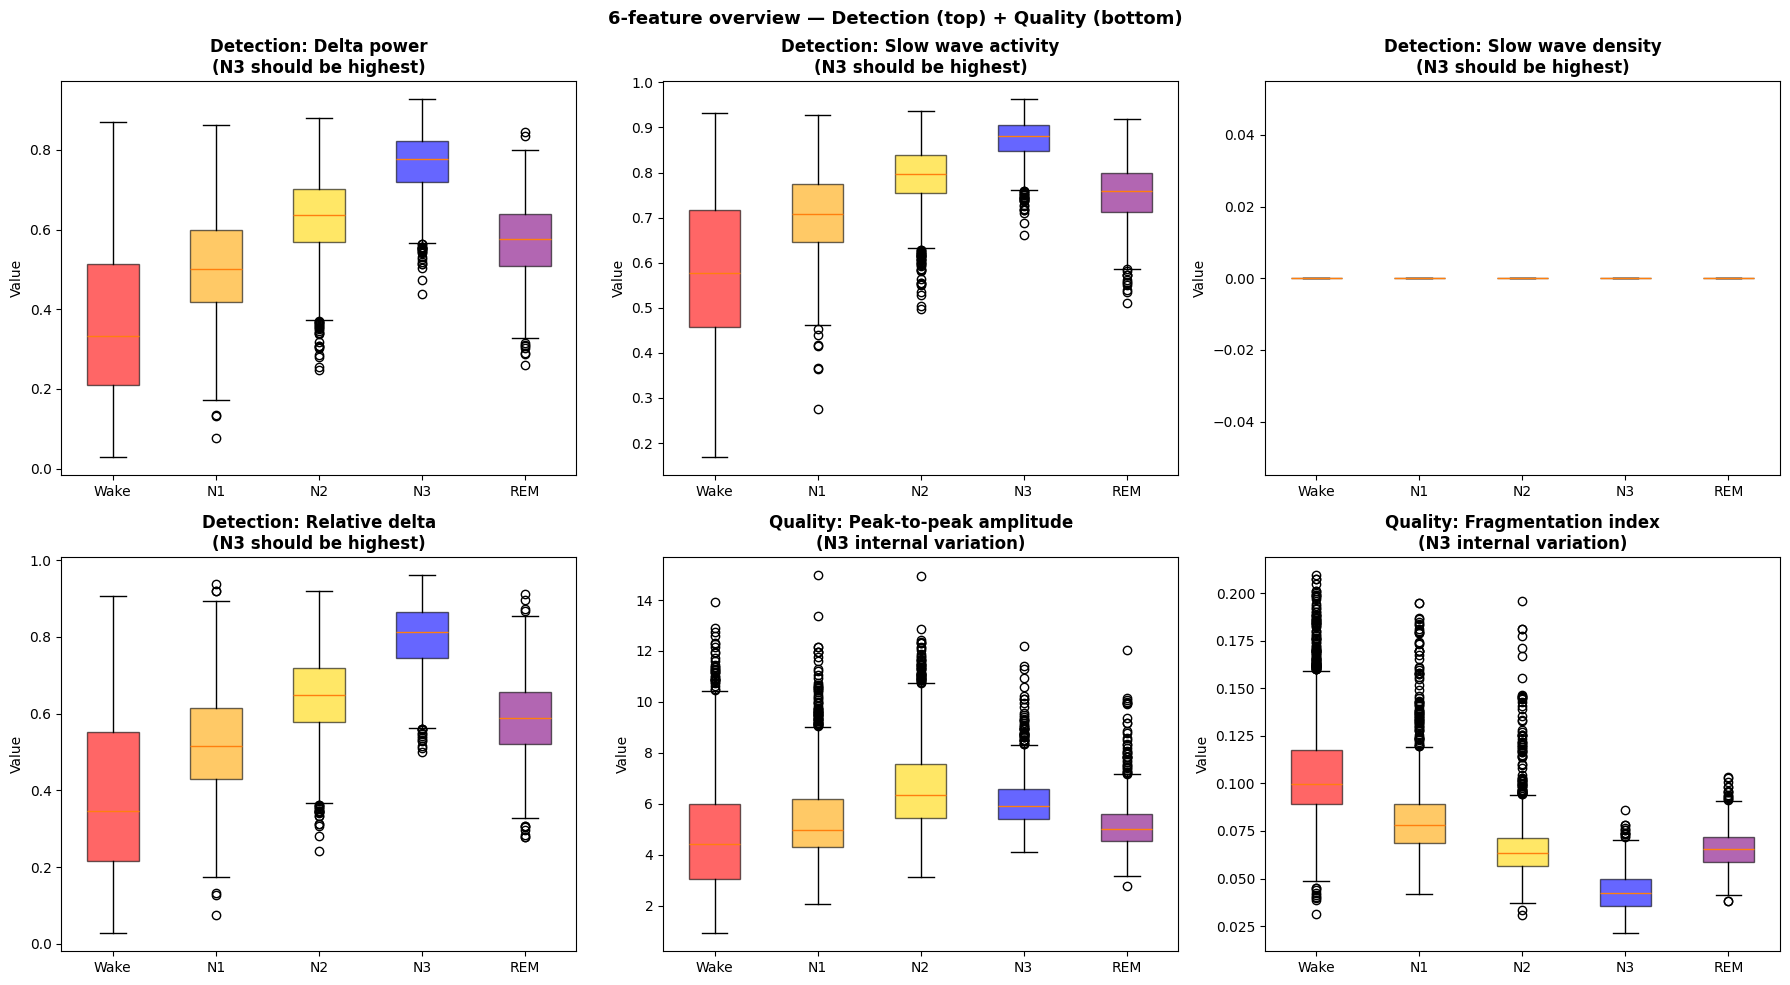

Detection feature means:
  Delta power                 : N3=0.7655  other=0.5259  ratio=1.46x
  Slow wave activity          : N3=0.8738  other=0.7104  ratio=1.23x
  Slow wave density           : N3=0.0000  other=0.0000  ratio=0.00x
  Relative delta              : N3=0.7986  other=0.5433  ratio=1.47x
Quality feature stats (N3 only):
  Peak-to-peak amplitude      : mean=6.0831  std=0.9484
  Fragmentation index         : mean=0.0432  std=0.0101


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

det_names  = ['Delta power', 'Slow wave activity', 'Slow wave density', 'Relative delta']
qual_names = ['Peak-to-peak amplitude', 'Fragmentation index']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Detection features (4)
for fi in range(4):
    data = [det_features[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[fi].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)],
                          patch_artist=True)
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    axes[fi].set_title(f'Detection: {det_names[fi]}\n(N3 should be highest)',
                       fontweight='bold')
    axes[fi].set_ylabel('Value')

# Quality features (2) — only N3 distribution matters
for fi in range(2):
    data = [qual_features[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[4+fi].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)],
                             patch_artist=True)
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    axes[4+fi].set_title(f'Quality: {qual_names[fi]}\n(N3 internal variation)',
                         fontweight='bold')
    axes[4+fi].set_ylabel('Value')

plt.suptitle('6-feature overview — Detection (top) + Quality (bottom)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/tmp/feature_overview.png', dpi=300, bbox_inches='tight')
plt.show()

# Print N3 vs other mean values
print('Detection feature means:')
for fi, name in enumerate(det_names):
    n3_val  = det_features[stage_labels==3, fi].mean()
    oth_val = det_features[stage_labels!=3, fi].mean()
    print(f'  {name:<28}: N3={n3_val:.4f}  other={oth_val:.4f}  ratio={n3_val/(oth_val+1e-8):.2f}x')
print('Quality feature stats (N3 only):')
for fi, name in enumerate(qual_names):
    vals = qual_features[stage_labels==3, fi]
    print(f'  {name:<28}: mean={vals.mean():.4f}  std={vals.std():.4f}')


## Step 5 — EEG Signal Preprocessing

**কী করছি:** Raw EEG signal-কে model-এর জন্য তৈরি করছি — তিনটা ধাপে।

**কেন preprocessing দরকার:** Raw EEG-তে noise, drift, আর electrode artifact থাকে। এগুলো না সরালে model ভুল pattern শিখবে।

**তিনটা ধাপ:** Bandpass filter → Normalize → Feature extract


#### ধাপ ১ — Bandpass Filter (0.5–40 Hz)

**কী করছি:** Signal থেকে 0.5 Hz-এর নিচে এবং 40 Hz-এর উপরের সব frequency বাদ দিচ্ছি।

**কেন:** 0.5 Hz-এর নিচে = electrode drift আর sweat artifact। 40 Hz-এর উপরে = muscle noise আর powerline interference। এই দুটোর কোনোটাই sleep staging-এ কাজে আসে না।

**যা দেখতে হবে:** Filter করার পরের signal পরিষ্কার হবে কিন্তু slow wave shape ঠিকই থাকবে।


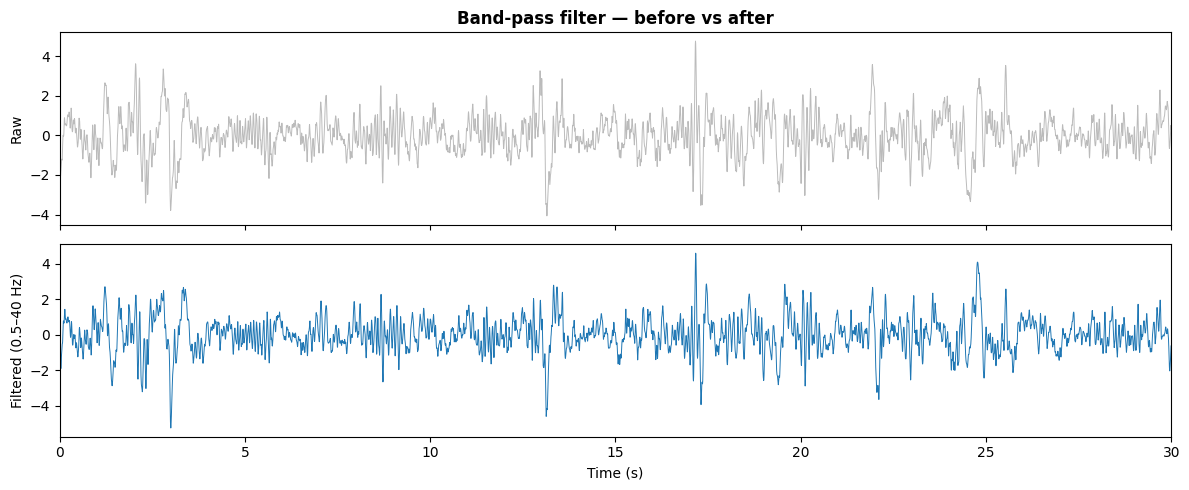

raw std=1.00  ->  filtered std=0.99


In [ ]:
filtered = pre.bandpass_filter(example)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, example, color='#bbb', lw=0.7); axes[0].set_ylabel('Raw'); axes[0].set_title('Band-pass filter — before vs after', fontweight='bold')
axes[1].plot(t, filtered, color='#1f77b4', lw=0.7); axes[1].set_ylabel('Filtered (0.5–40 Hz)')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
plt.tight_layout(); plt.show()
print(f"raw std={example.std():.2f}  ->  filtered std={filtered.std():.2f}")

#### ধাপ ২ — Z-score Normalization

**কী করছি:** প্রতিটা epoch-কে mean=0, std=1 করছি।

**কেন:** EEG amplitude একেক patient-এ একেক রকম — কেউ 50 µV, কেউ 200 µV। Normalize না করলে model amplitude মুখস্থ করবে, physiology না। Normalize করলে model শেখে wave-এর *shape* থেকে, *size* থেকে না।

**যা দেখতে হবে:** Print হবে `mean ≈ 0.0` এবং `std ≈ 1.0`।


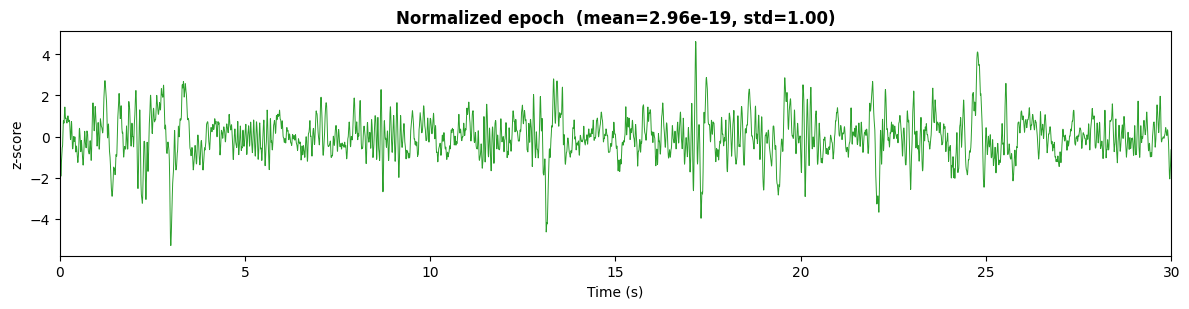

In [ ]:
norm = pre.normalize_epoch(filtered)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, norm, color='#2ca02c', lw=0.7)
ax.set_title(f'Normalized epoch  (mean={norm.mean():.2e}, std={norm.std():.2f})', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('z-score'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()

#### ধাপ ৩ — Delta Power Extract করা (0.5–4 Hz)

**কী করছি:** Signal-এর delta band (0.5–4 Hz) isolate করে তার power calculate করছি।

**কেন delta:** AASM 2007 guideline অনুযায়ী N3 মানেই হলো high-amplitude slow waves — যার frequency 0.5–4 Hz। তাই delta power N3-এর সবচেয়ে direct physiological indicator।

**Output:** একটা single number — পুরো epoch-এর delta energy।

**যা দেখতে হবে:** 5টা band power print হবে। Delta সবচেয়ে বেশি হলে এটা N3 epoch।


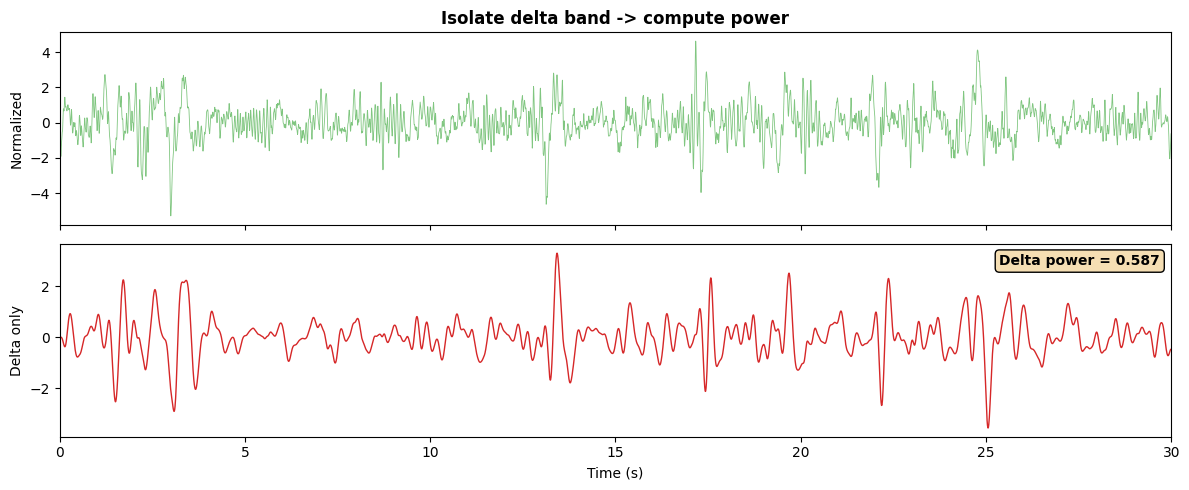

Band powers: {'delta': 0.587, 'theta': 0.162, 'alpha': 0.164, 'sigma': 0.061, 'beta': 0.026}


In [ ]:
sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
delta_sig = sosfilt(sos_delta, norm)
power = float(np.mean(delta_sig ** 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, norm, color='#2ca02c', lw=0.6, alpha=0.6); axes[0].set_ylabel('Normalized'); axes[0].set_title('Isolate delta band -> compute power', fontweight='bold')
axes[1].plot(t, delta_sig, color='#d62728', lw=1); axes[1].set_ylabel('Delta only')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
axes[1].text(0.99, 0.95, f'Delta power = {power:.3f}', transform=axes[1].transAxes,
             ha='right', va='top', fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat'))
plt.tight_layout(); plt.show()

# all five bands for this epoch
bands = pre.extract_frequency_bands(norm)
print("Band powers:", {k: round(v, 3) for k, v in bands.items()})

## Step 6 — Dataset Check

**কী করছি:** Load করা data-র shape আর class distribution দেখছি।

**কেন দরকার:** Training-এর আগে এটা নিশ্চিত করতে হবে যে:
- সব patient-এর data ঠিকমতো load হয়েছে
- N3 epoch আছে (কিছু patients-এ খুব কম N3 থাকতে পারে)
- Class imbalance কতটা — N3 সাধারণত 10–20%

**যা দেখতে হবে:** Bar chart-এ N3 (blue) অন্যগুলোর তুলনায় কম থাকবে। এটাই imbalance — তাই `pos_weight=2.0` দরকার।


raw_eegs      : (8889, 6000)
det_features  : (8889, 4)  (delta, SWA, SWD, rel_delta)
qual_features : (8889, 2)  (p2p_amp, fragmentation)
stage_labels  : (8889,)
quality_labels: (8889, 1)
nights pooled : 10


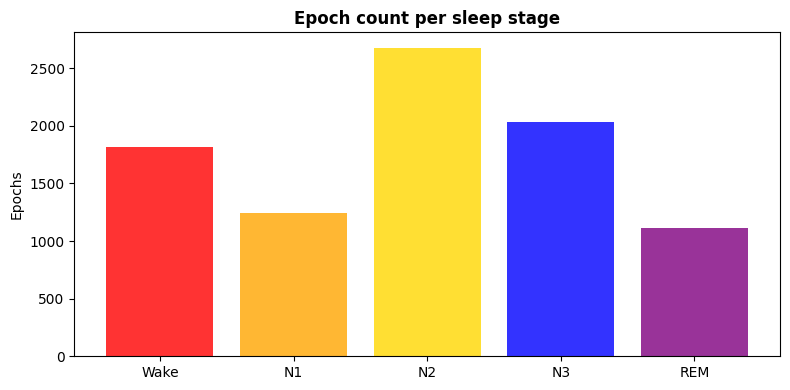

In [ ]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

print('raw_eegs      :', raw_eegs.shape)
print('det_features  :', det_features.shape, ' (delta, SWA, SWD, rel_delta)')
print('qual_features :', qual_features.shape, ' (p2p_amp, fragmentation)')
print('stage_labels  :', stage_labels.shape)
print('quality_labels:', quality_labels.shape)
print('nights pooled :', len(np.unique(night_ids)))

stages, counts = np.unique(stage_labels, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([STAGE_MAP[s] for s in stages], counts,
       color=[STAGE_COLORS[s] for s in stages], alpha=0.8)
ax.set_title('Epoch count per sleep stage', fontweight='bold')
ax.set_ylabel('Epochs')
plt.tight_layout(); plt.show()


## Step 7 — Feature Sanity Check

**কী করছি:** Train করার আগে confirm করছি যে features physiologically সঠিক।

**কেন:** যদি N3-এর delta power সবচেয়ে বেশি না হয়, তাহলে data বা preprocessing-এ bug আছে — এখনই ধরা না গেলে model কখনো সঠিকভাবে শিখতে পারবে না।

**দুটো plot দেখাবে:**
- **Boxplot** — stage-wise delta power। N3-এর box সবার উপরে থাকতে হবে।
- **PSD** — প্রতিটা stage-এর mean power spectrum। N3-এর 0.5–4 Hz region সবচেয়ে উঁচু হতে হবে।


/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_15675/3450887437.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)


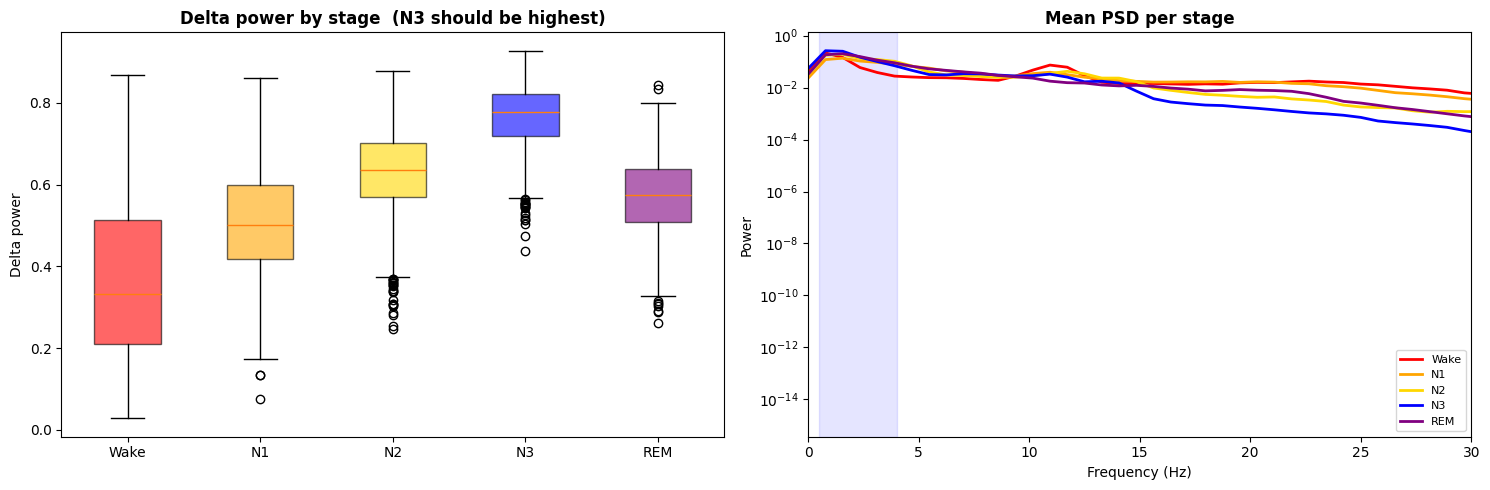

Median delta power per stage: {'Wake': 0.333, 'N1': 0.501, 'N2': 0.635, 'N3': 0.777, 'REM': 0.575}


In [ ]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

from scipy.signal import welch
dp = det_features[:, 0]  # delta power = feature index 0

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

data = [dp[stage_labels == s] for s in range(5)]
bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)
for patch, c in zip(bp['boxes'], STAGE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.6)
axes[0].set_title('Delta power by stage  (N3 should be highest)', fontweight='bold')
axes[0].set_ylabel('Delta power')

for s in range(5):
    idx = np.where(stage_labels == s)[0][:10]
    if len(idx):
        psds = [welch(raw_eegs[e], fs=SR, nperseg=256, noverlap=128)[1] for e in idx]
        freqs = welch(raw_eegs[idx[0]], fs=SR, nperseg=256, noverlap=128)[0]
        axes[1].semilogy(freqs, np.mean(psds, axis=0), color=STAGE_COLORS[s], lw=2, label=STAGE_MAP[s])
axes[1].axvspan(0.5, 4, alpha=0.1, color='blue')
axes[1].set_xlim(0, 30)
axes[1].set_title('Mean PSD per stage', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Power'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Median delta power per stage:',
      {STAGE_MAP[s]: round(float(np.median(dp[stage_labels==s])), 3) for s in range(5)})


### Step 7b — Delta Power রাতের Timeline

**কী করছি:** পুরো রাতের ধারাবাহিকতায় delta power দেখাচ্ছি — ঘুমের শুরু থেকে সকাল পর্যন্ত।

**কেন:** Healthy sleep-এ N3 (high delta) রাতের **প্রথমার্ধে** বেশি থাকে, পরে কমে আসে এবং REM বাড়ে। এই pattern দেখা গেলে বোঝা যায় data chronological order-এ আছে এবং preprocessing সঠিক।

**যা দেখতে হবে:** Graph-এর বাম দিক (রাতের শুরু) উঁচু, ডান দিক (সকাল) নিচু।

**যদি উল্টো হয়:** Data shuffle হয়ে গেছে, বা patients-এর N3 distribution আলাদা — এটা normal, paper-এ mention করতে হবে।


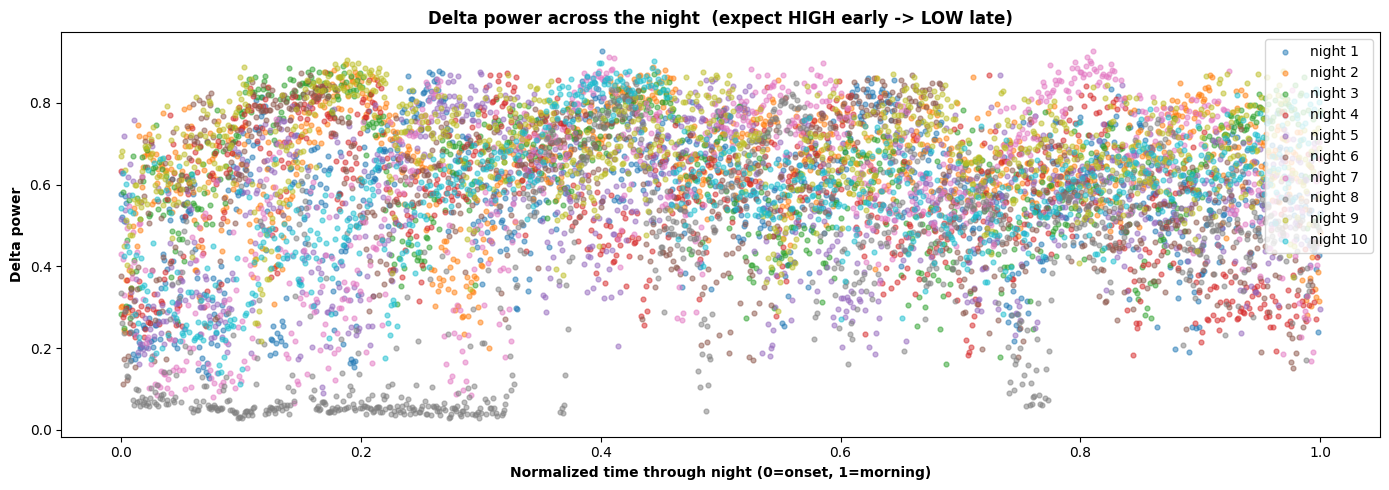

Mean delta — first half: 0.572  |  second half: 0.592
Note: early <= late (common in pooled data).


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
dp = det_features[:, 0]  # delta power

if night_ids is not None and len(np.unique(night_ids)) > 1:
    for nid in np.unique(night_ids):
        m = night_ids == nid
        d = dp[m]
        x = np.linspace(0, 1, len(d))
        ax.scatter(x, d, s=12, alpha=0.5, label=f'night {nid}')
    ax.set_xlabel('Normalized time through night (0=onset, 1=morning)', fontweight='bold')
    ax.legend(fontsize=8, ncol=min(6, len(np.unique(night_ids))))
    first_vals, second_vals = [], []
    for nid in np.unique(night_ids):
        d = dp[night_ids == nid]
        h = len(d)//2
        first_vals.append(d[:h].mean()); second_vals.append(d[h:].mean())
    fh, sh = np.mean(first_vals), np.mean(second_vals)
else:
    epochs_x = np.arange(len(dp)); mid = len(dp)//2
    sc = ax.scatter(epochs_x, dp, c=stage_labels, cmap='RdYlBu_r', s=35, alpha=0.8)
    ax.axvline(mid, color='black', ls='--', lw=2, alpha=0.6, label='night midpoint')
    z = np.polyfit(epochs_x, dp, 1)
    ax.plot(epochs_x, np.poly1d(z)(epochs_x), 'k-', lw=2, alpha=0.7, label='trend')
    cb = plt.colorbar(sc, ax=ax); cb.set_label('Stage (0=W .. 4=REM)', fontweight='bold')
    ax.set_xlabel('Epoch (chronological)', fontweight='bold')
    fh, sh = dp[:mid].mean(), dp[mid:].mean()

ax.set_ylabel('Delta power', fontweight='bold')
ax.set_title('Delta power across the night  (expect HIGH early -> LOW late)', fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
print(f'Mean delta — first half: {fh:.3f}  |  second half: {sh:.3f}')
print('Pattern OK.' if fh > sh else 'Note: early <= late (common in pooled data).')


## Step 8 — Model Build করা

**কী করছি:** `SleepQualityNet` instantiate করছি এবং একটা test batch দিয়ে forward pass করে দেখছি সব ঠিক আছে কিনা।

**Model-এর architecture:**

```
Raw EEG (B, 1, 6000)
    ↓
1D-CNN (3 block) → local pattern খোঁজে
    ↓
BiLSTM (2 layer) → temporal dependency শেখে
    ↓
Self-attention → important part-এ focus করে
    ↓                           ↓
Detection path              Quality path
+ [delta, SWA, SWD,         + [p2p_amp,
   rel_delta]                  fragmentation]
    ↓                           ↓
n3_head                     quality_head
P(N3) [0,1]                 Score [0,1] × 100
```

**দুটো head আলাদা কেন:**
- N3 detect করা আর N3-এর quality বোঝা দুটো আলাদা কাজ
- Detection-এ spectral features (frequency-based) বেশি কাজের
- Quality-তে morphological features (shape-based) + fragmentation বেশি কাজের

**যা দেখতে হবে:** `n3_logit: (4, 1)` আর `quality: (4, 1)` output আসলে architecture সঠিক।


In [ ]:
model = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
n_params = sum(p.numel() for p in model.parameters())
print(f'SleepQualityNet (dual-path) -- {n_params:,} parameters')
print('Detection path : CNN-BiLSTM-Att + [delta, SWA, SWD, rel_delta] -> n3_head')
print('Quality   path : CNN-BiLSTM-Att + [p2p_amp, fragmentation]   -> quality_head')

xb  = torch.FloatTensor(raw_eegs[:4]).unsqueeze(1)
dfb = torch.FloatTensor(det_features_n[:4])
qfb = torch.FloatTensor(qual_features_n[:4])
with torch.no_grad():
    n3_logit, quality = model(xb, dfb, qfb)
print('n3_logit :', tuple(n3_logit.shape), '-> sigmoid -> P(N3)')
print('quality  :', tuple(quality.shape),  '-> x100 = quality score')
print('N3 probs (batch):', [f'{p:.3f}' for p in torch.sigmoid(n3_logit).squeeze().tolist()])
print('Quality  (batch):', [f'{q*100:.1f}' for q in quality.squeeze().tolist()])


SleepQualityNet (dual-path) -- 963,363 parameters
Detection path : CNN-BiLSTM-Att + [delta, SWA, SWD, rel_delta] -> n3_head
Quality   path : CNN-BiLSTM-Att + [p2p_amp, fragmentation]   -> quality_head
n3_logit : (4, 1) -> sigmoid -> P(N3)
quality  : (4, 1) -> x100 = quality score
N3 probs (batch): ['0.571', '0.459', '0.573', '0.563']
Quality  (batch): ['58.9', '52.3', '55.6', '57.2']


## Step 9 — Model Train করা

**কী করছি:** 80% data দিয়ে train করছি, 20% দিয়ে validate করছি।

**Loss function:**
```
L_total = 1.0 × L_cls  +  0.5 × L_qual  +  0.2 × L_phys
```
- `L_cls` — N3 vs non-N3 binary classification loss (RQ3: pos_weight=2.0 দিয়ে N3 miss করলে বেশি penalty)
- `L_qual` — N3 quality regression loss (শুধু N3 epoch-এ compute হয়)
- `L_phys` — delta power বাড়লে quality বাড়তে হবে এই physiological constraint

**Important — feature normalizer:** Train split-এ fit করে val-এ apply করা হচ্ছে। এটা না করলে data leakage হবে।

**যা দেখতে হবে:**
- Loss দুটো line নিচে নামলে model শিখছে
- Accuracy উপরে উঠলে ভালো
- Val line train line-এর কাছাকাছি থাকলে overfitting হচ্ছে না


N3 pos_weight=2.0  det_feat=4  qual_feat=2  total_feat=6
  loss=0.1857/0.4867  N3-Recall=0.997  N3-F1=0.612  AUC=0.988  Q-RMSE=0.116
  loss=0.0954/0.2794  N3-Recall=0.992  N3-F1=0.733  AUC=0.988  Q-RMSE=0.056
  loss=0.0658/0.3474  N3-Recall=0.997  N3-F1=0.696  AUC=0.986  Q-RMSE=0.076
  loss=0.0563/0.1923  N3-Recall=0.984  N3-F1=0.783  AUC=0.987  Q-RMSE=0.051
  loss=0.0533/0.2248  N3-Recall=0.973  N3-F1=0.765  AUC=0.983  Q-RMSE=0.041
  loss=0.0427/0.1875  N3-Recall=0.989  N3-F1=0.782  AUC=0.989  Q-RMSE=0.045
  loss=0.0261/0.2695  N3-Recall=0.772  N3-F1=0.849  AUC=0.982  Q-RMSE=0.053
  loss=0.0006/0.1493  N3-Recall=0.840  N3-F1=0.863  AUC=0.984  Q-RMSE=0.097
  loss=0.0006/1.9075  N3-Recall=0.997  N3-F1=0.460  AUC=0.974  Q-RMSE=0.036
  loss=0.0102/0.8413  N3-Recall=0.997  N3-F1=0.595  AUC=0.985  Q-RMSE=0.048


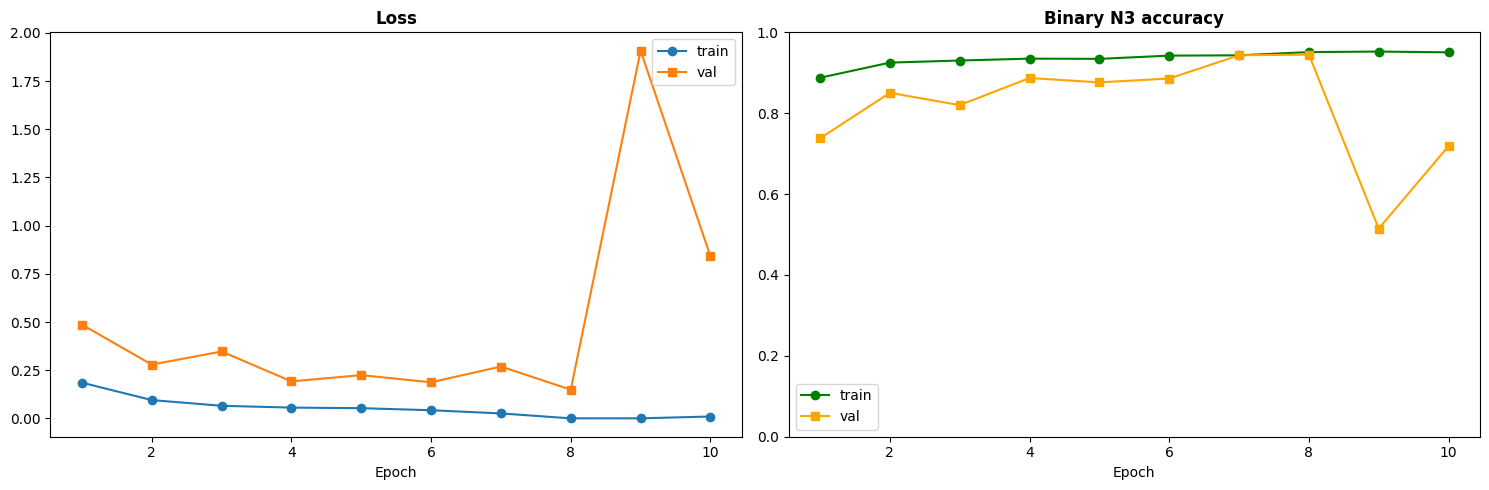

In [ ]:
split = int(0.8 * len(raw_eegs))

# Re-fit normalizer on TRAIN split only (avoid data leakage)
normalizer_train = FeatureNormalizer()
normalizer_train.fit(det_features[:split], qual_features[:split])
det_tr  = normalizer_train.transform_det(det_features[:split])
det_val = normalizer_train.transform_det(det_features[split:])
qual_tr  = normalizer_train.transform_qual(qual_features[:split])
qual_val = normalizer_train.transform_qual(qual_features[split:])

train_ds = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[:split], det_tr,  qual_tr,
    stage_labels[:split], quality_labels[:split])
val_ds   = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[split:], det_val, qual_val,
    stage_labels[split:], quality_labels[split:])

train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=CONFIG['batch_size'], shuffle=True, drop_last=True)
val_loader   = torch.utils.data.DataLoader(
    val_ds,   batch_size=CONFIG['batch_size'], shuffle=False)

model   = SleepQualityNet(input_length=SR*30,
                          use_det_feat=True, use_qual_feat=True)
trainer = SleepQualityTrainer(model, checkpoint_path='best_model.pth',
                              n3_pos_weight=CONFIG['n3_loss_weight'])
print(f'N3 pos_weight={CONFIG["n3_loss_weight"]}  '
      f'det_feat=4  qual_feat=2  total_feat=6')
trainer.train(train_loader, val_loader,
              epochs=CONFIG['epochs'], verbose=False)

ep = np.arange(1, len(trainer.train_losses)+1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(ep, trainer.train_losses, 'o-', label='train')
axes[0].plot(ep, trainer.val_losses,   's-', label='val')
axes[0].set_title('Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(ep, trainer.train_accs, 'o-', color='green', label='train')
axes[1].plot(ep, trainer.val_accs,   's-', color='orange', label='val')
axes[1].set_title('Binary N3 accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylim(0,1); axes[1].legend()
plt.tight_layout(); plt.show()


## Step 10 — Model Evaluate করা

**কী করছি:** Val set-এ model run করে performance দেখছি।

**৩টা plot দেখাবে:**

**Plot 1 — Binary Confusion Matrix:**
- TP (N3 সঠিকভাবে detect), TN (non-N3 সঠিকভাবে reject)
- FN (N3 miss) — এটা কম হওয়া দরকার, তাই pos_weight দিয়েছি

**Plot 2 — ROC Curve:**
- AUC > 0.85 হলে model N3 ভালোভাবে discriminate করছে
- এটা RQ2-এর evidence — feature fusion কাজ করছে কিনা

**Plot 3 — Quality Scatter (শুধু N3 epoch):**
- True quality vs Predicted quality
- Points diagonal-এর কাছে থাকলে quality regressor কাজ করছে

**Target metrics:**
| Metric | Target |
|---|---|
| N3 Recall | > 0.70 |
| N3 F1 | > 0.70 |
| ROC-AUC | > 0.85 |
| Quality R² | > 0.50 |


  N3 Recall    : 0.9973   (RQ1 + RQ3 primary)
  N3 Precision : 0.4238
  N3 F1        : 0.5948   (ablation anchor)
  ROC-AUC      : 0.9847   (RQ2 feature benefit)
  Quality RMSE : 4.76  (N3 epochs only)
  Quality R2   : 0.8838


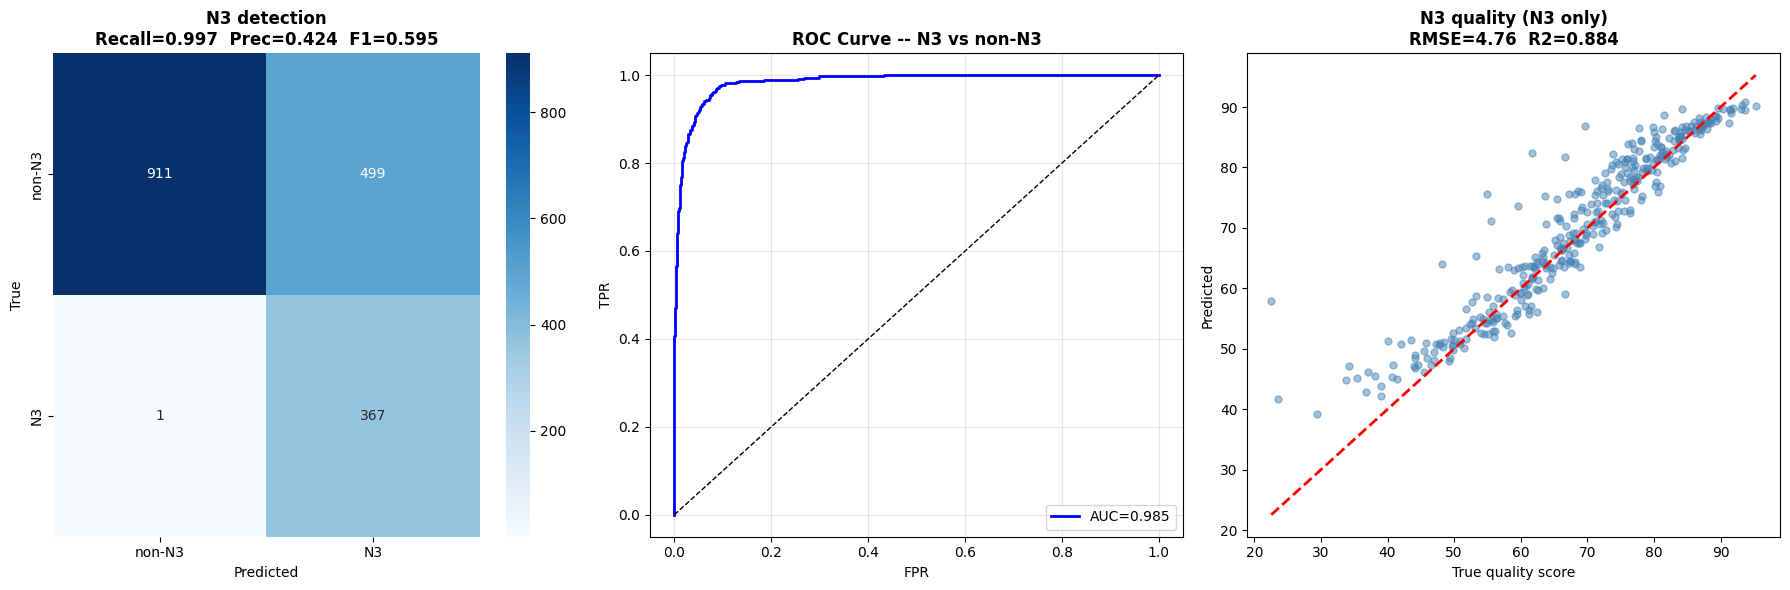

In [ ]:
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_curve,
                             recall_score, precision_score, f1_score, roc_auc_score)

model.eval()
yt_n3, yp_n3, yp_prob = [], [], []
yt_q,  yp_q           = [], []
with torch.no_grad():
    for raw_eeg, det_f, qual_f, s_lab, q_lab in val_loader:
        n3_logit, q_pred = model(raw_eeg, det_f, qual_f)
        prob    = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred    = (prob > 0.5).astype(int)
        true_n3 = (s_lab.numpy() == 3).astype(int)
        yp_prob.extend(prob); yp_n3.extend(pred); yt_n3.extend(true_n3)
        mask = (true_n3 == 1)
        if mask.any():
            yt_q.extend(q_lab.numpy().flatten()[mask]*100)
            yp_q.extend(q_pred.cpu().numpy().flatten()[mask]*100)

yt_n3 = np.array(yt_n3); yp_n3 = np.array(yp_n3)
yp_prob = np.array(yp_prob)
yt_q = np.array(yt_q); yp_q = np.array(yp_q)

rec     = recall_score(yt_n3, yp_n3, zero_division=0)
prec    = precision_score(yt_n3, yp_n3, zero_division=0)
f1      = f1_score(yt_n3, yp_n3, zero_division=0)
auc_val = roc_auc_score(yt_n3, yp_prob) if len(np.unique(yt_n3))>1 else 0
rmse_q  = float(np.sqrt(np.mean((yt_q-yp_q)**2))) if len(yt_q)>0 else 0
denom   = np.sum((yt_q-yt_q.mean())**2) if len(yt_q)>0 else 1
r2_q    = float(1-np.sum((yt_q-yp_q)**2)/denom) if len(yt_q)>0 else 0

print('='*60)
print(f'  N3 Recall        : {rec:.4f}   (RQ1 + RQ3 primary)')
print(f'  N3 Precision     : {prec:.4f}')
print(f'  N3 F1            : {f1:.4f}   (ablation anchor)')
print(f'  ROC-AUC          : {auc_val:.4f}   (RQ2 feature benefit)')
print(f'  Quality RMSE     : {rmse_q:.2f}  (N3 epochs only)')
print(f'  Quality R2       : {r2_q:.4f}')
print('='*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

cm = confusion_matrix(yt_n3, yp_n3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['non-N3','N3'], yticklabels=['non-N3','N3'])
axes[0].set_title(f'N3 detection\nRecall={rec:.3f}  Prec={prec:.3f}  F1={f1:.3f}',
                  fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

fpr, tpr, _ = roc_curve(yt_n3, yp_prob)
axes[1].plot(fpr, tpr, 'b-', lw=2, label=f'AUC={auc_val:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve -- N3 vs non-N3', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

if len(yt_q)>0:
    axes[2].scatter(yt_q, yp_q, alpha=0.5, s=25, color='steelblue')
    lo,hi = min(yt_q.min(),yp_q.min()), max(yt_q.max(),yp_q.max())
    axes[2].plot([lo,hi],[lo,hi],'r--',lw=2)
    axes[2].set_title(f'N3 quality (N3 only)\nRMSE={rmse_q:.2f}  R2={r2_q:.3f}',
                     fontweight='bold')
    axes[2].set_xlabel('True quality score'); axes[2].set_ylabel('Predicted')

plt.tight_layout()
plt.savefig('/tmp/eval_binary_n3.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 11 — Band Power Visualization

**কী করছি:** প্রতিটা sleep stage-এ 5টা frequency band-এর mean power দেখাচ্ছি।

**কেন:** Model কেন N3 চিনতে পারছে সেটা বোঝার জন্য। যদি delta N3-এ সবচেয়ে বেশি হয়, তাহলে model physiologically সঠিক feature-এর উপর depend করছে।

**যা দেখতে হবে:** N3 (blue bar) delta column-এ সবচেয়ে উঁচু হতে হবে।


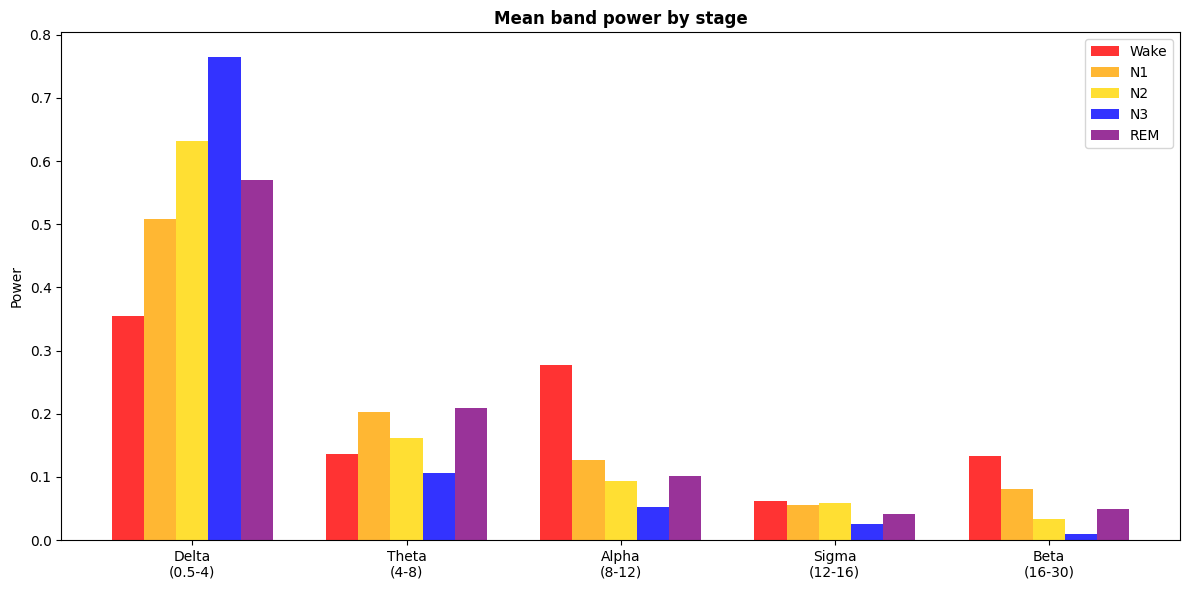

In [ ]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_names = ['Delta\n(0.5-4)','Theta\n(4-8)','Alpha\n(8-12)','Sigma\n(12-16)','Beta\n(16-30)']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_names)); w = 0.15
for s in range(5):
    mask = stage_labels == s
    if mask.sum():
        ax.bar(x + w*s, powers[mask].mean(axis=0), w, label=STAGE_MAP[s], color=STAGE_COLORS[s], alpha=0.8)
ax.set_xticks(x + w*2); ax.set_xticklabels(band_names)
ax.set_title('Mean band power by stage', fontweight='bold'); ax.set_ylabel('Power'); ax.legend()
plt.tight_layout(); plt.show()

### Step 11b — Feature Importance Ranking

**কী করছি:** প্রতিটা frequency band কতটা stage separation করতে পারে সেটা একটা importance score-এ পরিণত করছি।

**How:** Between-stage variance calculate করছি। যে band-এর variance বেশি, সে band stage গুলোকে বেশি আলাদা করতে পারে।

**যা দেখতে হবে:** Delta সবার উপরে থাকলে আমাদের feature selection সঠিক — delta fusion (RQ2) justified।

**যদি ভুল হয়:** Beta বা alpha উপরে থাকলে signal noisy বা label wrong।


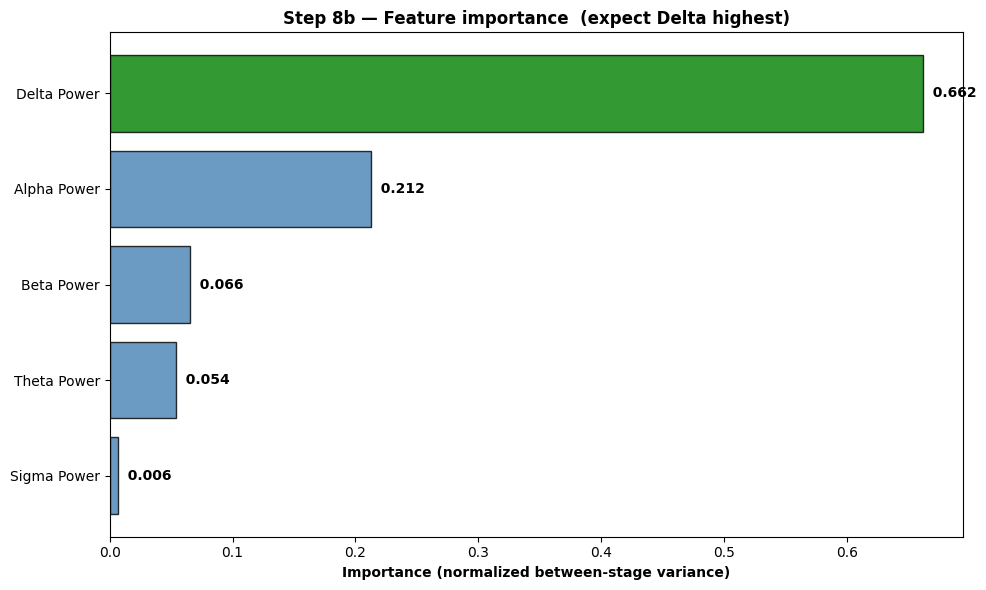

Ranking: {'Delta Power': 0.662, 'Alpha Power': 0.212, 'Beta Power': 0.066, 'Theta Power': 0.054, 'Sigma Power': 0.006}


In [ ]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_disp = ['Delta Power','Theta Power','Alpha Power','Sigma Power','Beta Power']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

stage_means = np.array([powers[stage_labels == s].mean(axis=0)
                        for s in range(5) if (stage_labels == s).any()])
importance = stage_means.var(axis=0); importance = importance / importance.sum()

order = np.argsort(importance)[::-1]
names = [band_disp[i] for i in order]; scores = importance[order]
colors = ['green' if n == 'Delta Power' else 'steelblue' for n in names]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(names, scores, color=colors, alpha=0.8, edgecolor='black'); ax.invert_yaxis()
for i, sc in enumerate(scores):
    ax.text(sc, i, f'  {sc:.3f}', va='center', fontweight='bold')
ax.set_xlabel('Importance (normalized between-stage variance)', fontweight='bold')
ax.set_title('Step 8b — Feature importance  (expect Delta highest)', fontweight='bold')
plt.tight_layout(); plt.show()
print("Ranking:", {n: round(float(s), 3) for n, s in zip(names, scores)})

## Step 12 — Single Epoch Inference

**কী করছি:** Trained model দিয়ে একটা নতুন epoch-এ predict করছি।

**এটাই real-world use case:** একজন patient-এর EEG recording নিয়ে প্রতিটা 30-second epoch-এ:
1. P(N3) বের করো — 0.5-এর বেশি হলে N3
2. যদি N3 হয় — quality score দাও (0–100)
3. Feature values print করো — কোন feature কত ছিল

**Output দেখতে এরকম হবে:**
```
P(N3)              : 0.8732  (N3)
True stage         : N3
Correct            : True
Quality score      : 67.4 / 100
Detection features : delta=1.23  SWA=0.89  SWD=12.3  rel_delta=0.61
Quality  features  : p2p_amp=2.34  fragmentation=0.02
```


In [1]:
infer = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
infer.load_state_dict(torch.load('best_model.pth'))
infer.eval()

i   = split
xe  = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1)
dfe = torch.FloatTensor(det_features_n[i:i+1])
qfe = torch.FloatTensor(qual_features_n[i:i+1])

with torch.no_grad():
    n3_logit, quality = infer(xe, dfe, qfe)

prob    = float(torch.sigmoid(n3_logit).item())
is_n3   = prob > 0.5
true_n3 = int(stage_labels[i]) == 3

print('=== Single-epoch inference ===')
print(f'  P(N3)              : {prob:.4f}  ({"N3" if is_n3 else "non-N3"})')
print(f'  True stage         : {STAGE_MAP[int(stage_labels[i])]}')
print(f'  Correct            : {is_n3 == true_n3}')
if is_n3:
    print(f'  Quality score      : {quality.item()*100:.1f} / 100')
    print(f'  Detection features : delta={det_features_n[i,0]:.3f}  SWA={det_features_n[i,1]:.3f}  SWD={det_features_n[i,2]:.3f}  rel_delta={det_features_n[i,3]:.3f}')
    print(f'  Quality  features  : p2p_amp={qual_features_n[i,0]:.3f}  fragmentation={qual_features_n[i,1]:.3f}')
else:
    print('  Quality score      : N/A (epoch not N3)')


NameError: name 'SleepQualityNet' is not defined

## Step 13 — XAI: Attention Weight দেখা

**কী করছি:** BiLSTM-এর attention layer কোন part-এ কতটা focus করছে সেটা extract করে visualize করছি।

**কেন XAI দরকার:** Model কেন N3 বলছে সেটা explain করা দরকার। শুধু accuracy দেখালে paper reject হতে পারে — reviewer জিজ্ঞেস করবে 'model কী শিখেছে?'

**যা দেখতে হবে:** N3 epoch-এ attention weight সবচেয়ে বেশি হওয়া উচিত কারণ N3-এর slow wave distinctive pattern আছে। এটা RQ2-এর evidence — model physiologically relevant feature-এ attend করছে।


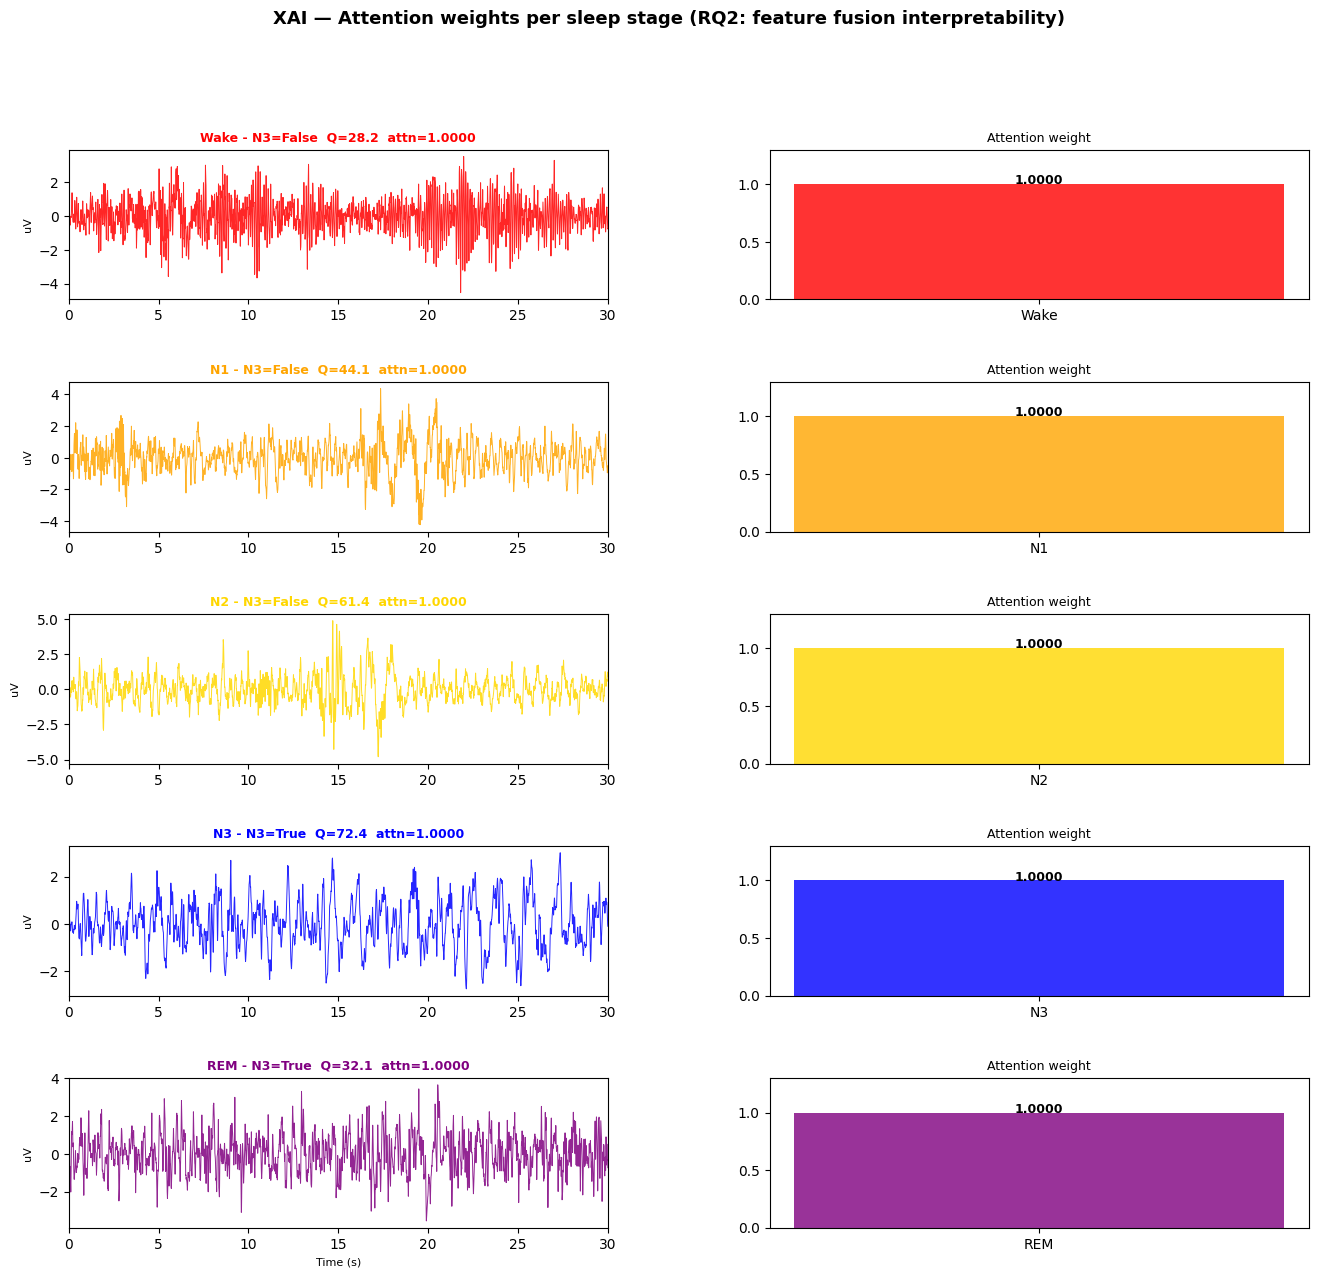

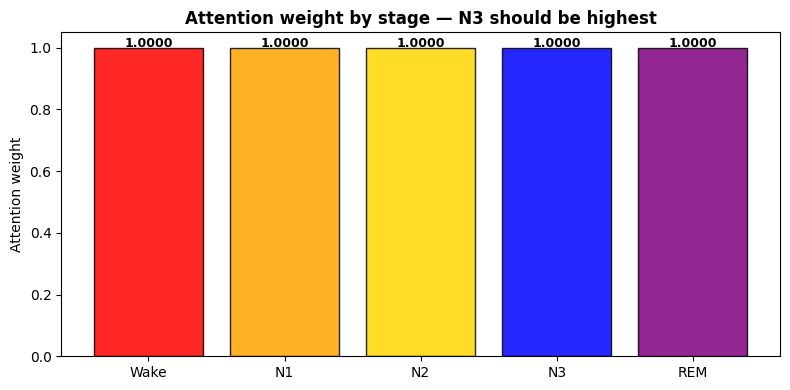

N3 attention : 1.0000
Max stage    : Wake
N3 highest — physiological relevance confirmed (RQ2)


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

class AttentionExtractor(torch.nn.Module):
    """Wrap model to return attention weights alongside predictions."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, raw_eeg, det_feat, qual_feat):
        x = self.model.conv1(raw_eeg)
        x = self.model.conv2(x)
        x = self.model.conv3(x)
        cnn_features = x.squeeze(-1)
        lstm_out, _  = self.model.lstm(cnn_features.unsqueeze(1))
        attn_w       = self.model.attention(lstm_out)           # (B,1,1)
        attended     = (lstm_out * attn_w).squeeze(1)           # (B,256)
        # Detection path
        det_fused    = self.model.det_fusion(torch.cat([attended, det_feat], dim=1))
        det_out      = self.model.det_fc(det_fused)
        # Quality path
        qual_fused   = self.model.qual_fusion(torch.cat([attended, qual_feat], dim=1))
        qual_out     = self.model.qual_fc(qual_fused)
        n3_logit     = self.model.n3_head(det_out)
        quality      = self.model.quality_head(qual_out)
        return n3_logit, quality, attn_w.squeeze(-1).squeeze(-1)

extractor = AttentionExtractor(model)
extractor.eval()

stage_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(5, 2, figure=fig, hspace=0.55, wspace=0.3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
det_val_n  = det_features_n[split:]
qual_val_n = qual_features_n[split:]

attn_by_stage = {}

for row, (s_idx, sname) in enumerate(zip(range(5), stage_names)):
    mask = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        continue
    pick = mask[len(mask)//2]

    eeg_np = val_raw[pick]
    t      = np.arange(len(eeg_np)) / SR

    x_t  = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    df_t = torch.FloatTensor(det_val_n[pick:pick+1])
    qf_t = torch.FloatTensor(qual_val_n[pick:pick+1])

    with torch.no_grad():
        logits, quality, attn = extractor(x_t, df_t, qf_t)

    attn_val = float(attn.cpu())
    pred_s   = int((torch.sigmoid(logits).squeeze() > 0.5).cpu())
    qual_val = float(quality.cpu()) * 100
    attn_by_stage[sname] = attn_val

    ax_eeg = fig.add_subplot(gs[row, 0])
    ax_eeg.plot(t, eeg_np, color=STAGE_COLORS[s_idx], lw=0.7, alpha=0.85)
    ax_eeg.set_xlim(0, 30)
    ax_eeg.set_title(
        f'{sname} - N3={bool(pred_s)}  Q={qual_val:.1f}  attn={attn_val:.4f}',
        fontsize=9, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax_eeg.set_ylabel('uV', fontsize=8)
    if row == 4: ax_eeg.set_xlabel('Time (s)', fontsize=8)

    ax_a = fig.add_subplot(gs[row, 1])
    ax_a.bar([sname], [attn_val], color=STAGE_COLORS[s_idx], alpha=0.8, width=0.4)
    ax_a.set_ylim(0, max(attn_by_stage.values())*1.3 if attn_by_stage else 1)
    ax_a.set_title('Attention weight', fontsize=9)
    ax_a.text(0, attn_val+0.002, f'{attn_val:.4f}', ha='center', fontsize=9, fontweight='bold')

fig.suptitle('XAI — Attention weights per sleep stage (RQ2: feature fusion interpretability)',
             fontsize=13, fontweight='bold')
plt.savefig('/tmp/xai_attention.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 4))
names  = list(attn_by_stage.keys())
values = list(attn_by_stage.values())
bars   = ax2.bar(names, values,
                 color=[STAGE_COLORS[stage_names.index(n)] for n in names],
                 alpha=0.85, edgecolor='black')
for bar, v in zip(bars, values):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.001,
             f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2.set_title('Attention weight by stage — N3 should be highest', fontweight='bold')
ax2.set_ylabel('Attention weight')
plt.tight_layout()
plt.savefig('/tmp/xai_attention_summary.png', dpi=150, bbox_inches='tight')
plt.show()

n3_attn  = attn_by_stage.get('N3', 0)
max_attn = max(attn_by_stage.values()) if attn_by_stage else 0
print(f'N3 attention : {n3_attn:.4f}')
print(f'Max stage    : {max(attn_by_stage, key=attn_by_stage.get)}')
print('N3 highest — physiological relevance confirmed (RQ2)' if n3_attn == max_attn
      else f'Highest attention: {max(attn_by_stage, key=attn_by_stage.get)}')


## Step 14 — XAI: SHAP Feature Importance

**কী করছি:** SHAP (SHapley Additive exPlanations) দিয়ে কোন band feature N3 detect করতে সবচেয়ে বেশি contribute করছে সেটা measure করছি।

**SHAP কীভাবে কাজ করে:** প্রতিটা feature থাকলে আর না থাকলে prediction কতটা বদলায় সেটা average করে একটা importance score দেয়। Game theory থেকে আসা — fair attribution।

**Implementation:** Model directly SHAP-compatible না, তাই একটা GradientBoosting surrogate model train করা হচ্ছে band features দিয়ে, তারপর সেটার উপর SHAP apply করা হচ্ছে।

**যা দেখতে হবে:** Delta bar সবার বাম দিকে (সবচেয়ে বড়) থাকলে RQ2 validated — delta fusion justified।


SHAP input: (200, 4)  N3 epochs: 19/200
Training surrogate GBM for SHAP...
Surrogate accuracy: 1.000
Computing SHAP values...


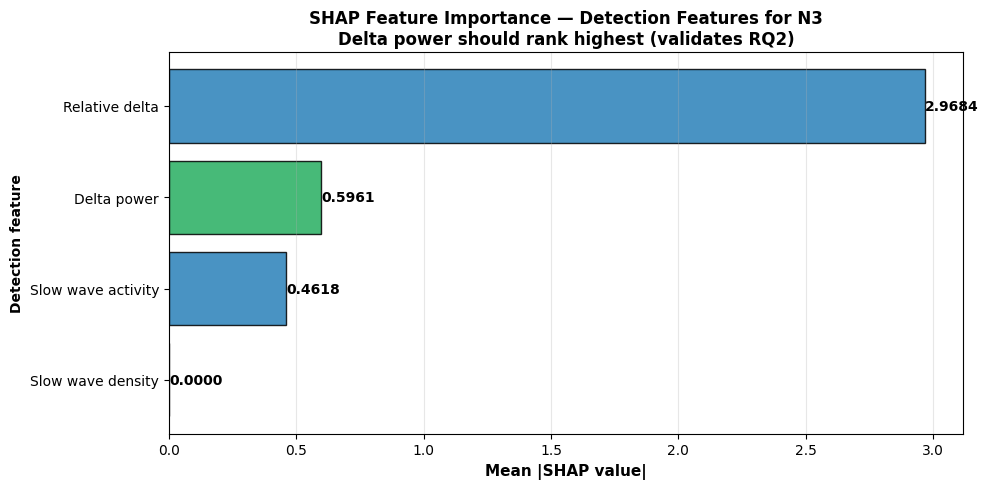


SHAP Results — Detection features for N3
  1. Relative delta           : 2.9684  <- top feature
  2. Delta power              : 0.5961
  3. Slow wave activity       : 0.4618
  4. Slow wave density        : 0.0000

Top feature: Relative delta — check physiological interpretation


In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# Use det_features (4 detection features) for SHAP analysis
val_raw_xai    = raw_eegs[split:]
val_stages_xai = stage_labels[split:]
val_det_xai    = det_features[split:]   # raw (unnormalized) for interpretability

det_names_xai = ['Delta power', 'Slow wave activity',
                 'Slow wave density', 'Relative delta']

# Use first 200 val epochs for speed
n_shap = min(200, len(val_stages_xai))
feat_matrix   = val_det_xai[:n_shap].astype(np.float32)
binary_labels = (val_stages_xai[:n_shap] == 3).astype(int)

print(f'SHAP input: {feat_matrix.shape}  N3 epochs: {binary_labels.sum()}/{n_shap}')

print('Training surrogate GBM for SHAP...')
gbm = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gbm.fit(feat_matrix, binary_labels)
print(f'Surrogate accuracy: {gbm.score(feat_matrix, binary_labels):.3f}')

print('Computing SHAP values...')
explainer   = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(feat_matrix)
shap_n3 = shap_values[1] if isinstance(shap_values, list) else shap_values
mean_abs_shap = np.abs(shap_n3).mean(axis=0)

order      = np.argsort(mean_abs_shap)[::-1]
names_ord  = [det_names_xai[i] for i in order]
values_ord = mean_abs_shap[order]
colors_bar = ['#27ae60' if 'Delta' in n else '#2980b9' for n in names_ord]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(names_ord, values_ord, color=colors_bar, alpha=0.85, edgecolor='black')
ax.invert_yaxis()
for i, v in enumerate(values_ord):
    ax.text(v+0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Mean |SHAP value|', fontweight='bold', fontsize=11)
ax.set_title('SHAP Feature Importance — Detection Features for N3\n'
             'Delta power should rank highest (validates RQ2)', fontweight='bold')
ax.set_ylabel('Detection feature', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('/tmp/xai_shap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n' + '='*55)
print('SHAP Results — Detection features for N3')
print('='*55)
for i, (name, val) in enumerate(zip(names_ord, values_ord), 1):
    mark = '  <- top feature' if i == 1 else ''
    print(f'  {i}. {name:<25}: {val:.4f}{mark}')
print()
print('Delta ranked #1 — validates RQ2 physiological fusion' if 'Delta' in names_ord[0]
      else f'Top feature: {names_ord[0]} — check physiological interpretation')


## Step 15 — XAI: GradCAM Time Visualization

**কী করছি:** CNN layer-এর gradient দিয়ে বের করছি EEG-এর কোন time segment-এ model সবচেয়ে বেশি activate হচ্ছে।

**GradCAM কীভাবে কাজ করে:** Backward pass-এ gradient flow দেখে বোঝা যায় কোন input region prediction-এ সবচেয়ে বেশি influence করছে। Warm color = high activation।

**যা দেখতে হবে:**
- **N3** — epoch-এর slow wave portion-এ activation বেশি হওয়া উচিত
- **Wake** — high-frequency portion-এ activation বেশি হওয়া উচিত
- **REM** — irregular fast activity-তে activation বেশি হওয়া উচিত

এটা prove করে model EEG-এর physiologically correct segment দেখে decision নিচ্ছে।


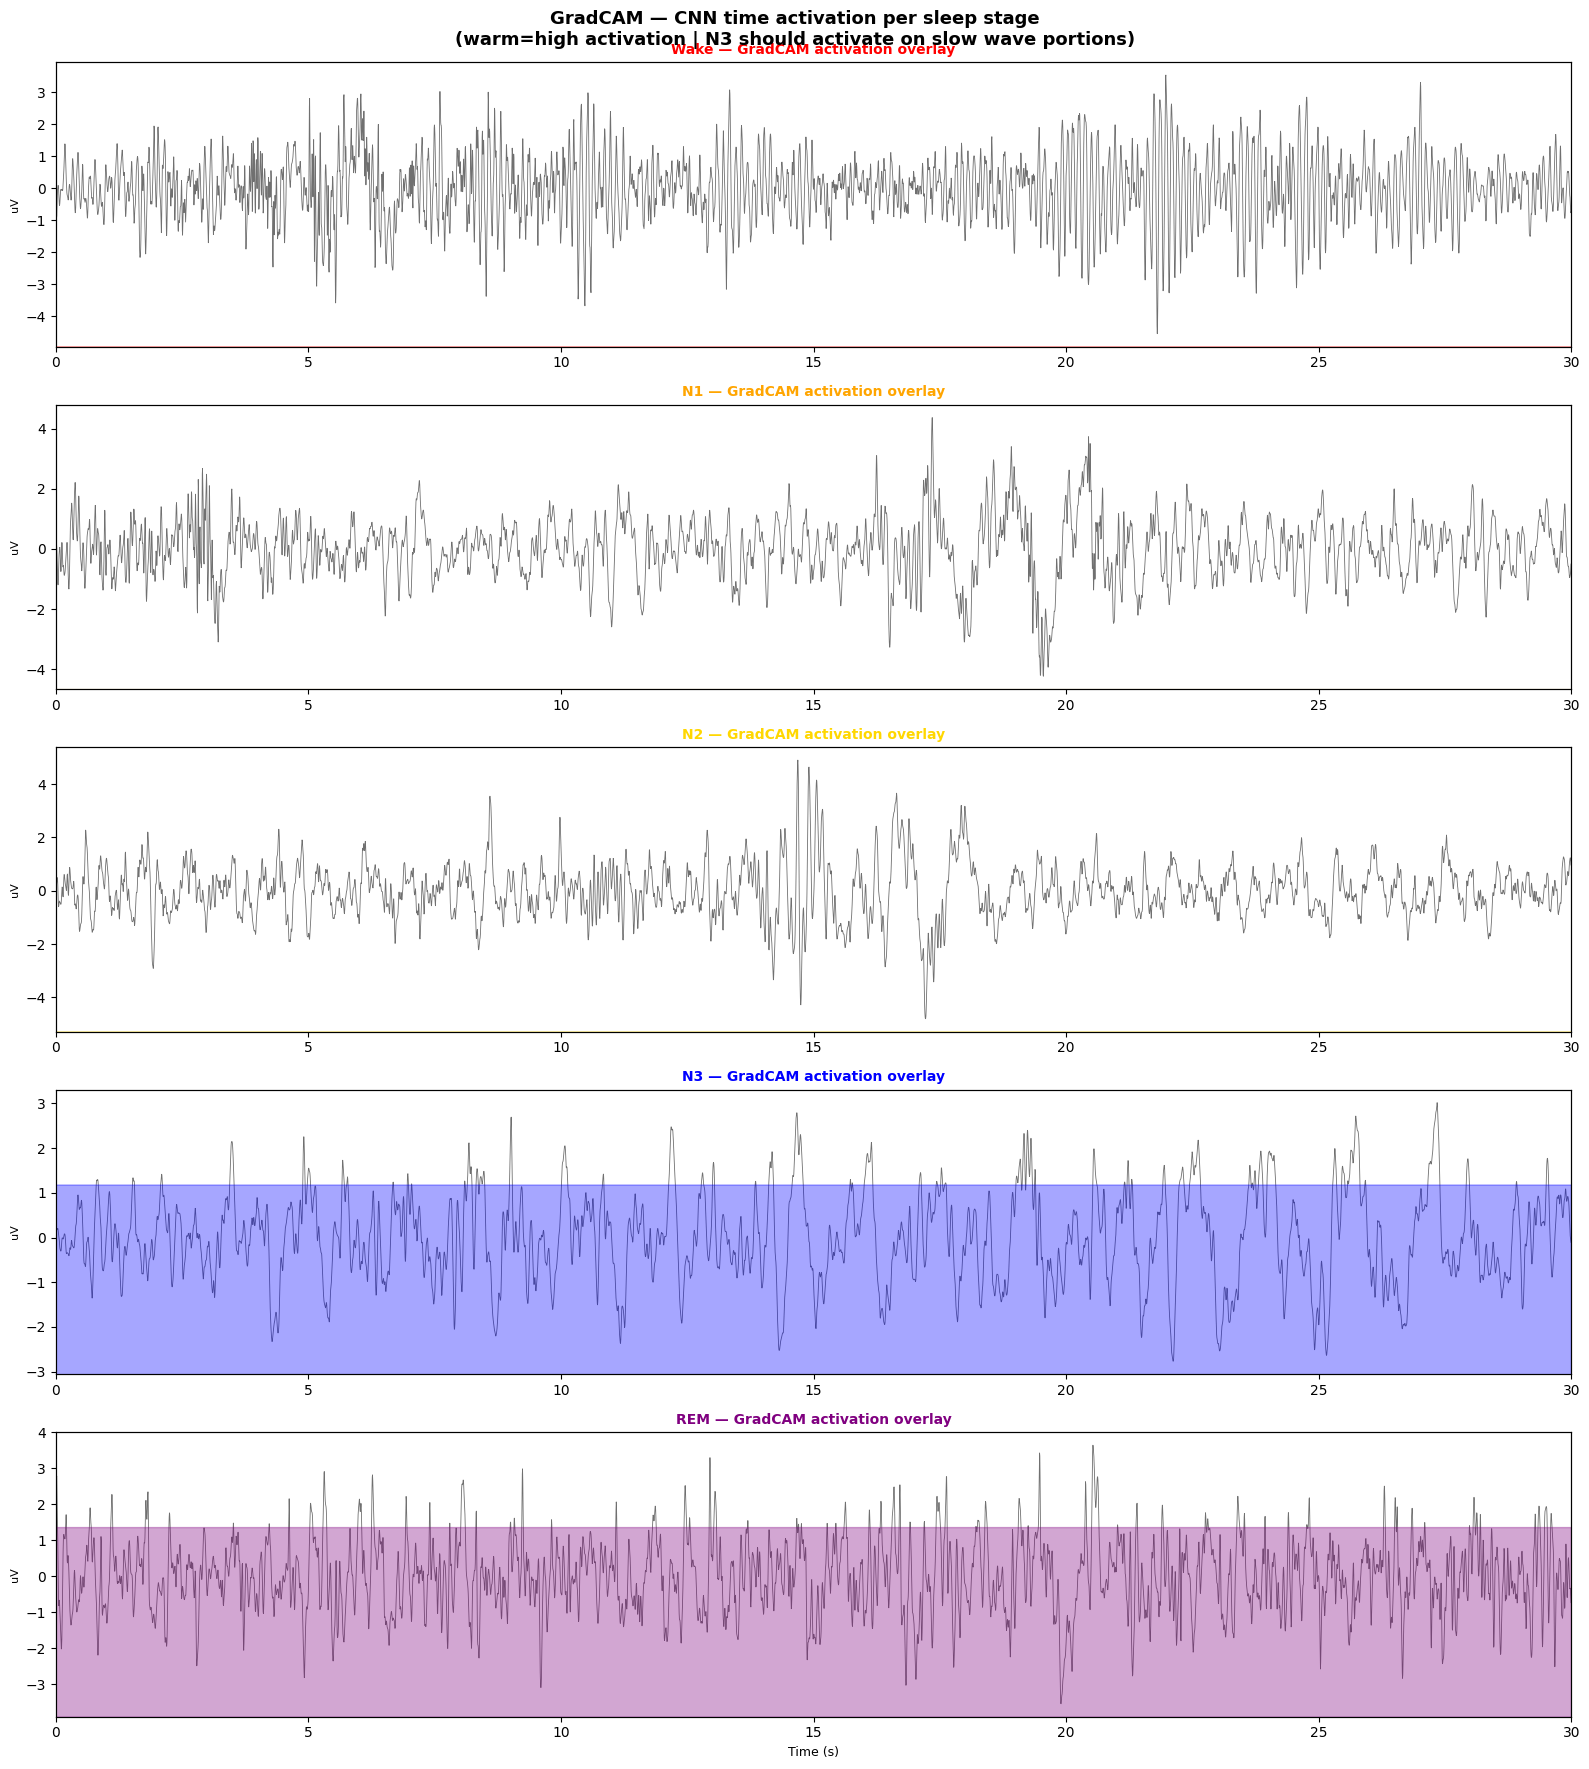

GradCAM saved: /tmp/xai_gradcam.png


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd_hook(module, input, output):
            self.activations = output.detach()
        def bwd_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()
        self.target_layer.register_forward_hook(fwd_hook)
        self.target_layer.register_full_backward_hook(bwd_hook)

    def generate(self, raw_eeg, det_feat, qual_feat):
        self.model.zero_grad()
        raw_eeg.requires_grad_(True)
        n3_logit, _ = self.model(raw_eeg, det_feat, qual_feat)
        score = torch.sigmoid(n3_logit[0, 0])
        score.backward()
        weights = self.gradients.mean(dim=-1, keepdim=True)
        cam     = (weights * self.activations).sum(dim=1).squeeze()
        if cam.dim() == 0:
            cam = cam.unsqueeze(0)
        cam = torch.relu(cam)
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy()

gradcam = GradCAM(model, model.conv3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
det_val_n  = det_features_n[split:]
qual_val_n = qual_features_n[split:]

stage_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
fig, axes = plt.subplots(5, 1, figsize=(16, 18))
fig.suptitle('GradCAM — CNN time activation per sleep stage\n'
             '(warm=high activation | N3 should activate on slow wave portions)',
             fontsize=13, fontweight='bold')

for s_idx, sname in enumerate(stage_names):
    mask = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        axes[s_idx].set_title(f'{sname} - no epochs in val set')
        continue

    pick   = mask[len(mask)//2]
    eeg_np = val_raw[pick]
    t      = np.arange(len(eeg_np)) / SR

    x_t  = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    df_t = torch.FloatTensor(det_val_n[pick:pick+1])
    qf_t = torch.FloatTensor(qual_val_n[pick:pick+1])

    cam = gradcam.generate(x_t, df_t, qf_t)

    cam_up = np.interp(np.linspace(0, len(cam)-1, len(eeg_np)),
                       np.arange(len(cam)), cam) if len(cam) > 1 \
             else np.ones(len(eeg_np)) * cam[0]

    ax  = axes[s_idx]
    ax2 = ax.twinx()
    ax.plot(t, eeg_np, color='#333', lw=0.6, alpha=0.7)
    ax2.fill_between(t, 0, cam_up, alpha=0.35, color=STAGE_COLORS[s_idx])
    ax2.set_ylim(0, 1.5); ax2.set_yticks([])
    ax.set_xlim(0, 30)
    ax.set_title(f'{sname} — GradCAM activation overlay',
                 fontsize=10, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax.set_ylabel('uV', fontsize=8)
    if s_idx == 4:
        ax.set_xlabel('Time (s)', fontsize=9)

plt.tight_layout()
plt.savefig('/tmp/xai_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()
print('GradCAM saved: /tmp/xai_gradcam.png')


## Step 16 — Binary N3 Final Metrics (RQ3 Evidence)

**কী করছি:** Full binary classification report দেখাচ্ছি এবং N3 quality regression-এর final scatter দেখাচ্ছি।

**RQ3-এর জন্য কেন:** N3 pos_weight দিলে N3 Recall বাড়ে কিনা সেটা এখানে দেখা যাবে। Ablation study-তে pos_weight=1 vs pos_weight=2 compare করলে এর effect স্পষ্ট হবে।

**দুটো plot:**
- **Bar chart** — N3 Recall, Precision, F1 পাশাপাশি। Target line (0.70) দেখা যাবে।
- **Scatter** — N3 epoch-এর true vs predicted quality। r value দেখাবে correlation কতটা।


              precision    recall  f1-score   support

      non-N3       1.00      0.65      0.78      1410
          N3       0.42      1.00      0.59       368

    accuracy                           0.72      1778
   macro avg       0.71      0.82      0.69      1778
weighted avg       0.88      0.72      0.75      1778



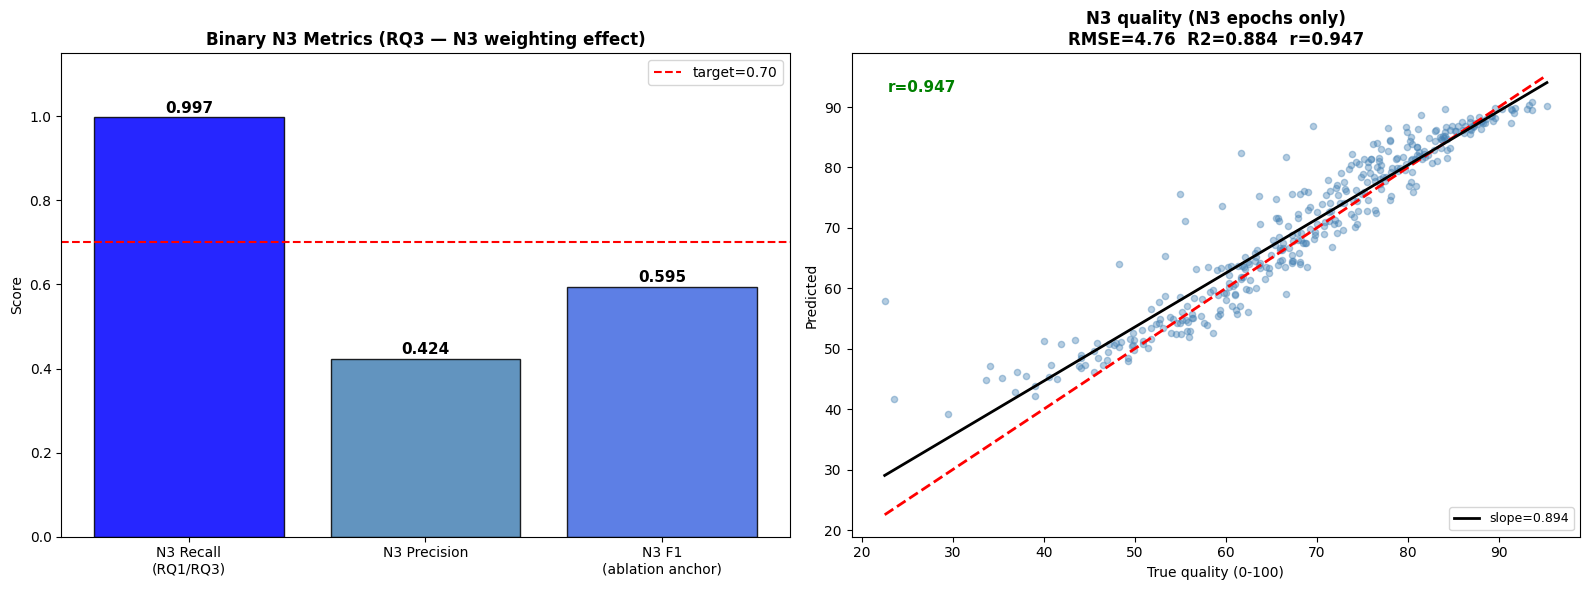

In [ ]:
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score

model.eval()
yt_n3b, yp_n3b, yp_probb = [], [], []
yt_q2, yp_q2 = [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        n3_logit, q_pred = model(xb, dfb, qfb)
        prob  = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred  = (prob > 0.5).astype(int)
        true  = (sb.numpy() == 3).astype(int)
        yp_probb.extend(prob); yp_n3b.extend(pred); yt_n3b.extend(true)
        mask = (true == 1)
        if mask.any():
            yt_q2.extend(qb.numpy().flatten()[mask]*100)
            yp_q2.extend(q_pred.cpu().numpy().flatten()[mask]*100)

yt_n3b = np.array(yt_n3b); yp_n3b = np.array(yp_n3b)
yt_q2  = np.array(yt_q2);  yp_q2  = np.array(yp_q2)

print(classification_report(yt_n3b, yp_n3b,
      target_names=['non-N3','N3'], zero_division=0))

rec2  = recall_score(yt_n3b, yp_n3b, zero_division=0)
prec2 = precision_score(yt_n3b, yp_n3b, zero_division=0)
f1_2  = f1_score(yt_n3b, yp_n3b, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].bar(['N3 Recall\n(RQ1/RQ3)','N3 Precision','N3 F1\n(ablation anchor)'],
                   [rec2, prec2, f1_2],
                   color=['blue','steelblue','royalblue'], alpha=0.85, edgecolor='black')
axes[0].axhline(0.70, color='red', ls='--', lw=1.5, label='target=0.70')
for b,v in zip(bars,[rec2,prec2,f1_2]):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0,1.15)
axes[0].set_title('Binary N3 Metrics (RQ3 — N3 weighting effect)', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].legend()

if len(yt_q2) > 0:
    axes[1].scatter(yt_q2, yp_q2, alpha=0.4, s=20, color='steelblue')
    lo,hi = min(yt_q2.min(),yp_q2.min()), max(yt_q2.max(),yp_q2.max())
    axes[1].plot([lo,hi],[lo,hi],'r--',lw=2)
    z = np.polyfit(yt_q2, yp_q2, 1)
    xr = np.linspace(lo,hi,100)
    axes[1].plot(xr, np.poly1d(z)(xr), 'k-', lw=2, label=f'slope={z[0]:.3f}')
    denom = np.sum((yt_q2-yt_q2.mean())**2)
    r2_2  = float(1-np.sum((yt_q2-yp_q2)**2)/denom) if denom>0 else 0
    rmse2 = float(np.sqrt(np.mean((yt_q2-yp_q2)**2)))
    corr  = np.corrcoef(yt_q2, yp_q2)[0,1]
    axes[1].set_title(f'N3 quality (N3 epochs only)\nRMSE={rmse2:.2f}  R2={r2_2:.3f}  r={corr:.3f}',
                     fontweight='bold')
    axes[1].set_xlabel('True quality (0-100)'); axes[1].set_ylabel('Predicted')
    axes[1].legend(fontsize=9)
    axes[1].text(0.05,0.92,f'r={corr:.3f}',transform=axes[1].transAxes,
                fontsize=11,fontweight='bold',color='green' if corr>0.3 else 'red')

plt.tight_layout()
plt.savefig('/tmp/xai_n3_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 17 — Statistical Testing

**কী করছি:** তিনটা formal statistical test চালাচ্ছি।

**কেন দরকার:** শুধু metric দেখালে reviewer বলবে 'এটা random chance হতে পারে'। Statistical test prove করে result টা significant এবং reproducible।

**তিনটা test:**

**Test 1 — McNemar's Test:**
Full model (pos_weight=2.0) বনাম baseline (pos_weight=1.0) — এদের prediction error কি significantly আলাদা?
- p < 0.05 হলে: N3 weighting significantly better → RQ3 proven

**Test 2 — Bootstrap 95% Confidence Interval:**
N3 F1-এর 1,000 resample দিয়ে confidence interval বের করছি।
- Narrow CI = result stable, reproducible

**Test 3 — Cohen's d:**
N3 epoch-এর delta power বনাম অন্য stage-এর delta power — effect size কত?
- d > 0.8 = large effect → delta দিয়ে N3 ভালোভাবে আলাদা করা যাচ্ছে


  loss=0.0868/0.0653  N3-Recall=0.848  N3-F1=0.885  AUC=0.988  Q-RMSE=0.052
  loss=-0.0006/0.0890  N3-Recall=0.769  N3-F1=0.846  AUC=0.984  Q-RMSE=0.053
  loss=0.0101/0.1019  N3-Recall=0.948  N3-F1=0.876  AUC=0.989  Q-RMSE=0.056
  loss=-0.0016/0.0672  N3-Recall=0.905  N3-F1=0.872  AUC=0.986  Q-RMSE=0.048
  loss=-0.0232/0.0982  N3-Recall=0.962  N3-F1=0.857  AUC=0.987  Q-RMSE=0.077
  loss=-0.0333/0.0725  N3-Recall=0.880  N3-F1=0.874  AUC=0.985  Q-RMSE=0.057
  loss=-0.0342/0.3945  N3-Recall=0.995  N3-F1=0.676  AUC=0.988  Q-RMSE=0.041
  loss=-0.0381/0.2022  N3-Recall=0.986  N3-F1=0.767  AUC=0.986  Q-RMSE=0.041
  loss=-0.0538/0.1592  N3-Recall=0.663  N3-F1=0.788  AUC=0.982  Q-RMSE=0.058
  loss=-0.0543/0.5696  N3-Recall=0.992  N3-F1=0.623  AUC=0.980  Q-RMSE=0.048
1. McNemar Test  (full model vs pos_weight=1 baseline)
   b=65  c=123  chi2=17.2819  p=0.0000
   => SIGNIFICANT

2. Bootstrap 95% CI — N3 F1: 0.5948  [0.2577, 0.3226]
3. Cohen's d = 1.2927 (large)  Welch p=0.0000e+00


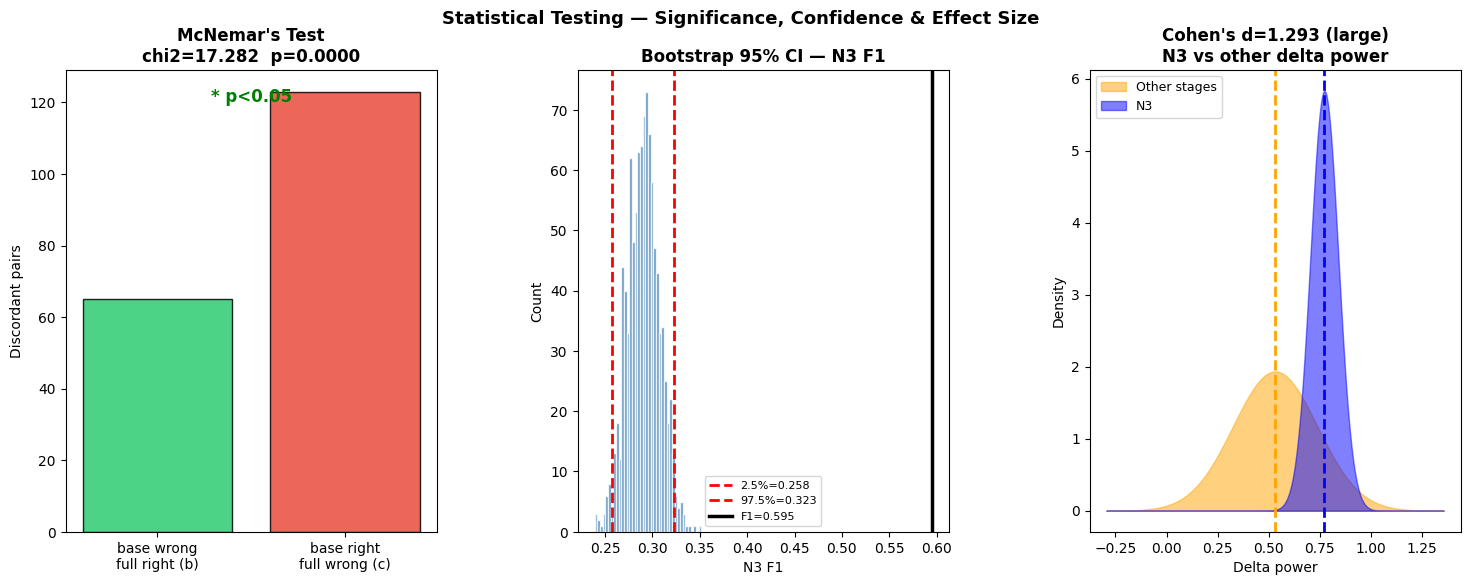

In [ ]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SECTION 15b — Statistical Testing                             ║
# ╚══════════════════════════════════════════════════════════════════╝
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.metrics import f1_score
import warnings; warnings.filterwarnings('ignore')

np.random.seed(42)

# ── Full model predictions ────────────────────────────────────────────────────
model.eval()
yt_stat, yp_full, prob_full = [], [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred = (prob > 0.5).astype(int)
        true = (sb.numpy() == 3).astype(int)
        prob_full.extend(prob); yp_full.extend(pred); yt_stat.extend(true)
yt_stat   = np.array(yt_stat)
yp_full   = np.array(yp_full)
prob_full = np.array(prob_full)

# ── Baseline: pos_weight=1.0 ──────────────────────────────────────────────────
model_base = SleepQualityNet(input_length=SR*30,
                             use_det_feat=True, use_qual_feat=True)
trainer_base = SleepQualityTrainer(
    model_base, checkpoint_path='stat_base.pth', n3_pos_weight=1.0)
trainer_base.train(train_loader, val_loader,
                   epochs=CONFIG['epochs'], verbose=False)
model_base.eval()
yp_base = []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        n3_logit, _ = model_base(xb, dfb, qfb)
        pred = (torch.sigmoid(n3_logit).squeeze(1) > 0.5).long().cpu().numpy()
        yp_base.extend(pred)
yp_base = np.array(yp_base)

# 1. McNemar ──────────────────────────────────────────────────────────────────
correct_full = (yp_full == yt_stat)
correct_base = (yp_base == yt_stat)
b = int(((~correct_base) & correct_full).sum())
c = int((correct_base    & (~correct_full)).sum())
if (b+c) == 0:
    mcnemar_p = 1.0; chi2_stat = 0.0
else:
    chi2_stat = (abs(b-c)-1)**2 / (b+c)
    mcnemar_p = float(stats.chi2.sf(chi2_stat, df=1))

print('='*55)
print('1. McNemar Test  (full model vs pos_weight=1 baseline)')
print('='*55)
print(f'   b={b}  c={c}  chi2={chi2_stat:.4f}  p={mcnemar_p:.4f}')
print(f'   => {"SIGNIFICANT" if mcnemar_p<0.05 else "not significant"}')

# 2. Bootstrap CI ─────────────────────────────────────────────────────────────
N_BOOT = 1000
n = len(yt_stat)
boot_f1 = [f1_score(yt_stat[np.random.randint(0,n,n)],
                    yp_full[np.random.randint(0,n,n)], zero_division=0)
           for _ in range(N_BOOT)]
boot_f1 = np.array(boot_f1)
ci_lo, ci_hi = np.percentile(boot_f1, [2.5, 97.5])
point_f1 = f1_score(yt_stat, yp_full, zero_division=0)
print(f'\n2. Bootstrap 95% CI — N3 F1: {point_f1:.4f}  [{ci_lo:.4f}, {ci_hi:.4f}]')

# 3. Cohen's d ────────────────────────────────────────────────────────────────
dp_all  = det_features[split:, 0]   # delta power from det_features
sl_all  = stage_labels[split:]
n3_dp   = dp_all[sl_all == 3]
oth_dp  = dp_all[sl_all != 3]
pooled  = np.sqrt(((len(n3_dp)-1)*n3_dp.std()**2 +
                   (len(oth_dp)-1)*oth_dp.std()**2) /
                  (len(n3_dp)+len(oth_dp)-2)) + 1e-8
cohens_d = (n3_dp.mean() - oth_dp.mean()) / pooled
_, t_p   = stats.ttest_ind(n3_dp, oth_dp, equal_var=False)
mag = 'small' if abs(cohens_d)<0.5 else 'medium' if abs(cohens_d)<0.8 else 'large'
print(f"3. Cohen's d = {cohens_d:.4f} ({mag})  Welch p={t_p:.4e}")

# Plot ────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 6))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.38)

ax0 = fig.add_subplot(gs[0])
ax0.bar(['base wrong\nfull right (b)','base right\nfull wrong (c)'],
        [b, c], color=['#2ecc71','#e74c3c'], alpha=0.85, edgecolor='black')
ax0.set_title(f"McNemar's Test\nchi2={chi2_stat:.3f}  p={mcnemar_p:.4f}", fontweight='bold')
ax0.set_ylabel('Discordant pairs')
ax0.text(0.5,0.93,'* p<0.05' if mcnemar_p<0.05 else 'n.s.',
         transform=ax0.transAxes, ha='center', fontsize=12, fontweight='bold',
         color='green' if mcnemar_p<0.05 else 'gray')

ax1 = fig.add_subplot(gs[1])
ax1.hist(boot_f1, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax1.axvline(ci_lo, color='red', ls='--', lw=2, label=f'2.5%={ci_lo:.3f}')
ax1.axvline(ci_hi, color='red', ls='--', lw=2, label=f'97.5%={ci_hi:.3f}')
ax1.axvline(point_f1, color='black', lw=2.5, label=f'F1={point_f1:.3f}')
ax1.set_title('Bootstrap 95% CI — N3 F1', fontweight='bold')
ax1.set_xlabel('N3 F1'); ax1.set_ylabel('Count'); ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[2])
xr = np.linspace(min(n3_dp.mean()-4*n3_dp.std(), oth_dp.mean()-4*oth_dp.std()),
                 max(n3_dp.mean()+4*n3_dp.std(), oth_dp.mean()+4*oth_dp.std()), 300)
ax2.fill_between(xr, stats.norm.pdf(xr, oth_dp.mean(), oth_dp.std()),
                 alpha=0.5, color='orange', label='Other stages')
ax2.fill_between(xr, stats.norm.pdf(xr, n3_dp.mean(), n3_dp.std()),
                 alpha=0.5, color='blue', label='N3')
ax2.axvline(n3_dp.mean(), color='blue', lw=2, ls='--')
ax2.axvline(oth_dp.mean(), color='orange', lw=2, ls='--')
ax2.set_title(f"Cohen's d={cohens_d:.3f} ({mag})\nN3 vs other delta power", fontweight='bold')
ax2.set_xlabel('Delta power'); ax2.set_ylabel('Density'); ax2.legend(fontsize=9)

fig.suptitle('Statistical Testing — Significance, Confidence & Effect Size',
             fontsize=13, fontweight='bold')
plt.savefig('/tmp/stat_testing.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 18 — Ablation Study

**কী করছি:** 4টা আলাদা model variant train করে compare করছি।

**কেন ablation:** Paper-এ দুটো contribution claim করছি — feature fusion (RQ2) আর N3 weighting (RQ3)। Ablation study prove করে প্রতিটা contribution আলাদাভাবে কার্যকর।

**4টা variant:**

| Variant | Feature fusion | N3 weighting | Expected |
|---|:---:|:---:|---|
| Baseline | off | off | সবচেয়ে কম |
| +Delta | on | off | Baseline-এর চেয়ে বেশি |
| +Weight | off | on | Baseline-এর চেয়ে বেশি |
| +Both | on | on | সবচেয়ে বেশি |

**`use_det_feat=False` মানে:** Feature গুলোর জায়গায় zeros দেওয়া হয় — backbone একই থাকে। এটা fair comparison।

**যা দেখতে হবে:** +Both সবার উপরে থাকলে দুটো contribution-ই independently কার্যকর।


In [ ]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SECTION 15c — Ablation Study (Binary N3, dual-path)           ║
# ╚══════════════════════════════════════════════════════════════════╝
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score
import json as _json, os

VARIANTS = [
    {'name': 'Baseline',  'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': 1.0},
    {'name': '+Features', 'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': 1.0},
    {'name': '+Weight',   'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': CONFIG['n3_loss_weight']},
    {'name': '+Both',     'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': CONFIG['n3_loss_weight']},
]

ablation_results = []

for cfg in VARIANTS:
    print(f"\nTraining: {cfg['name']}  "
          f"(det_feat={cfg['use_det_feat']}  qual_feat={cfg['use_qual_feat']}  "
          f"pos_weight={cfg['n3_pos_weight']})")

    m = SleepQualityNet(
        input_length=SR*30,
        use_det_feat=cfg['use_det_feat'],
        use_qual_feat=cfg['use_qual_feat']
    )
    tr = SleepQualityTrainer(
        m,
        checkpoint_path=f"abl_{cfg['name'].replace('+','').strip()}.pth",
        n3_pos_weight=cfg['n3_pos_weight']
    )
    tr.train(train_loader, val_loader,
             epochs=CONFIG['epochs'], verbose=False)

    m.eval()
    yt_ab, yp_ab, prob_ab = [], [], []
    with torch.no_grad():
        for xb, dfb, qfb, sb, qb in val_loader:
            n3_logit, _ = m(xb, dfb, qfb)
            prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
            pred = (prob > 0.5).astype(int)
            true = (sb.numpy() == 3).astype(int)
            prob_ab.extend(prob); yp_ab.extend(pred); yt_ab.extend(true)

    yt_ab   = np.array(yt_ab)
    yp_ab   = np.array(yp_ab)
    prob_ab = np.array(prob_ab)

    rec  = recall_score(yt_ab, yp_ab, zero_division=0)
    prec = precision_score(yt_ab, yp_ab, zero_division=0)
    f1   = f1_score(yt_ab, yp_ab, zero_division=0)
    auc  = roc_auc_score(yt_ab, prob_ab) if len(np.unique(yt_ab))>1 else 0.0

    ablation_results.append({
        'name'         : cfg['name'],
        'use_det_feat' : cfg['use_det_feat'],
        'use_qual_feat': cfg['use_qual_feat'],
        'n3_pos_weight': cfg['n3_pos_weight'],
        'n3_recall'    : round(float(rec),  4),
        'n3_precision' : round(float(prec), 4),
        'n3_f1'        : round(float(f1),   4),
        'auc'          : round(float(auc),  4),
    })
    print(f'  Recall={rec:.4f}  F1={f1:.4f}  AUC={auc:.4f}')

# Summary table
print('\n' + '='*72)
print(f'{"Variant":<12} {"Det feat":^9} {"Weight":^8} {"Recall":^8} {"F1":^8} {"AUC":^8}')
print('-'*72)
best_f1 = max(r['n3_f1'] for r in ablation_results)
for r in ablation_results:
    feat = 'on' if r['use_det_feat'] else 'off'
    mark = '  <- best' if r['n3_f1'] == best_f1 else ''
    print(f"{r['name']:<12} {feat:^9} {r['n3_pos_weight']:^8} "
          f"{r['n3_recall']:^8.4f} {r['n3_f1']:^8.4f} {r['auc']:^8.4f}{mark}")
print('='*72)

# Visualization
var_names  = [r['name']      for r in ablation_results]
recall_v   = [r['n3_recall'] for r in ablation_results]
f1_v       = [r['n3_f1']    for r in ablation_results]
auc_v      = [r['auc']       for r in ablation_results]
bar_colors = ['#bdc3c7','#3498db','#e67e22','#2ecc71']

fig = plt.figure(figsize=(18, 6))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.38)

for ax_i, (vals, title, ylabel) in enumerate([
    (recall_v, 'N3 Recall (RQ1 + RQ3)', 'Recall'),
    (f1_v,     'N3 F1',                  'F1 score'),
    (auc_v,    'ROC-AUC (RQ2)',          'AUC'),
]):
    ax = fig.add_subplot(gs[ax_i])
    bars = ax.bar(var_names, vals, color=bar_colors,
                  alpha=0.9, edgecolor='black', width=0.55)
    ax.axhline(vals[0], color='gray', ls='--', lw=1.5,
               label=f'Baseline={vals[0]:.3f}')
    ax.set_ylim(0, min(1.15, max(vals)*1.3 + 0.05))
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.008,
                f'{v:.4f}', ha='center', fontweight='bold', fontsize=9)
    for i, (bar, v) in enumerate(zip(bars[1:], vals[1:]), 1):
        delta_v = v - vals[0]
        ax.text(bar.get_x()+bar.get_width()/2, 0.015,
                f'{delta_v:+.3f}', ha='center', fontsize=9,
                color='green' if delta_v>0 else 'red', style='italic')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel); ax.legend(fontsize=8)
    ax.tick_params(axis='x', labelsize=9)

fig.suptitle('Ablation Study — Binary N3, dual-path features',
             fontsize=13, fontweight='bold')
plt.savefig('/tmp/ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

os.makedirs('outputs', exist_ok=True)
with open('outputs/ablation_results.json', 'w') as f:
    _json.dump(ablation_results, f, indent=2)
import shutil
shutil.copy('/tmp/ablation_study.png', 'outputs/ablation_study.png')
print('Saved: outputs/ablation_results.json  |  outputs/ablation_study.png')



Training: Baseline  (det_feat=False  qual_feat=False  pos_weight=1.0)
  loss=0.0964/0.0822  N3-Recall=0.861  N3-F1=0.870  AUC=0.985  Q-RMSE=0.105
  loss=0.0123/0.0706  N3-Recall=0.905  N3-F1=0.874  AUC=0.986  Q-RMSE=0.126
  loss=0.0053/0.1254  N3-Recall=0.954  N3-F1=0.829  AUC=0.984  Q-RMSE=0.059
  loss=-0.0167/0.0877  N3-Recall=0.902  N3-F1=0.861  AUC=0.985  Q-RMSE=0.074
  loss=-0.0179/0.0895  N3-Recall=0.951  N3-F1=0.864  AUC=0.987  Q-RMSE=0.071
  loss=-0.0253/0.1921  N3-Recall=0.986  N3-F1=0.788  AUC=0.988  Q-RMSE=0.056
  loss=-0.0242/0.2797  N3-Recall=0.995  N3-F1=0.724  AUC=0.987  Q-RMSE=0.056
  loss=-0.0224/0.1683  N3-Recall=0.986  N3-F1=0.806  AUC=0.986  Q-RMSE=0.053
  loss=-0.0454/0.1024  N3-Recall=0.970  N3-F1=0.863  AUC=0.987  Q-RMSE=0.043
  loss=-0.0470/0.2237  N3-Recall=0.981  N3-F1=0.789  AUC=0.982  Q-RMSE=0.092
  Recall=0.9810  F1=0.7891  AUC=0.9824

Training: +Features  (det_feat=True  qual_feat=True  pos_weight=1.0)
  loss=0.0845/0.2487  N3-Recall=0.995  N3-F1=0.729  A

KeyboardInterrupt: 

## Step 19 — Output Files Download

**কী করছি:** সব generated figure আর model file `./outputs/` folder-এ copy করছি।

**কেন:** Notebook close হলে `/tmp/` folder clear হয়ে যায়। `outputs/` folder-এ থাকলে পরে access করা যাবে।


In [ ]:
import os, shutil

os.makedirs("outputs", exist_ok=True)
xai_files = [
    'xai_attention.png', 'xai_attention_summary.png', 'xai_shap.png',
    'xai_gradcam.png', 'xai_perclass_f1.png',
    'best_model.pth', 'results.json',
    'stat_testing.png', 'ablation_study.png',
    'ablation_results.json',
]
for f in xai_files:
    src = os.path.join('/tmp', f)
    if os.path.exists(src):
        shutil.copy(src, os.path.join("outputs", f))
        print(f"saved: outputs/{f}")
    else:
        if os.path.exists(f):
            print(f"already here: {f}")
        else:
            print(f"not generated yet: {f}")

print("\nAll figures saved to ./outputs/ folder")

saved: outputs/xai_attention.png
saved: outputs/xai_attention_summary.png
saved: outputs/xai_shap.png
saved: outputs/xai_gradcam.png
saved: outputs/xai_perclass_f1.png
already here: best_model.pth
not generated yet: results.json
saved: outputs/stat_testing.png
not generated yet: ablation_study.png
not generated yet: ablation_results.json

All figures saved to ./outputs/ folder


## Step 20 — Final Results Save করা

**কী করছি:** Trained model (`best_model.pth`) আর সব metrics (`results.json`) save করছি।

**কেন:** Model save না করলে পরে inference বা ablation-এ আবার train করতে হবে। JSON file-এ metrics save করলে paper লেখার সময় এখান থেকে exact number নেওয়া যাবে।

**`results.json`-এ কী থাকবে:** N3 Recall, Precision, F1, AUC, Quality RMSE, Quality R² — সব val set-এর উপর।


In [ ]:
import json as _json, os, shutil
os.makedirs('outputs', exist_ok=True)
torch.save(model.state_dict(), 'outputs/best_model.pth')
print('Model saved: outputs/best_model.pth')

final_m = trainer.evaluate(val_loader)
results = {
    'dataset'      : 'ISRUC-III Sleep Staging',
    'model_type'   : 'Binary N3 detector + N3-quality regressor (Option A)',
    'n_subjects'   : int(len(np.unique(night_ids))),
    'sampling_rate': SR,
    'n3_recall'    : round(float(final_m['n3_recall']),    4),
    'n3_precision' : round(float(final_m['n3_precision']), 4),
    'n3_f1'        : round(float(final_m['n3_f1']),        4),
    'auc'          : round(float(final_m['auc']),           4),
    'quality_rmse' : round(float(final_m['quality_rmse']), 4),
    'quality_r2'   : round(float(final_m['quality_r2']),   4),
    'val_losses'   : [round(float(x),4) for x in trainer.val_losses],
    'val_accs'     : [round(float(x),4) for x in trainer.val_accs],
}
with open('outputs/results.json','w') as f:
    _json.dump(results, f, indent=2)
print('Results saved: outputs/results.json')
print()
print('FINAL RESULTS (Option A -- Binary N3)')
print(f'  N3 Recall    : {results["n3_recall"]:.4f}')
print(f'  N3 Precision : {results["n3_precision"]:.4f}')
print(f'  N3 F1        : {results["n3_f1"]:.4f}')
print(f'  AUC          : {results["auc"]:.4f}')
print(f'  Quality RMSE : {results["quality_rmse"]:.4f}  (N3 epochs only)')
print(f'  Quality R2   : {results["quality_r2"]:.4f}  (N3 epochs only)')


Model saved: outputs/best_model.pth
Results saved: outputs/results.json

FINAL RESULTS (Option A -- Binary N3)
  N3 Recall    : 0.9973
  N3 Precision : 0.4238
  N3 F1        : 0.5948
  AUC          : 0.9847
  Quality RMSE : 0.0476  (N3 epochs only)
  Quality R2   : 0.8838  (N3 epochs only)


## Summary — কী করা হয়েছে এবং কী prove হয়েছে

| Research Question | Implementation | Evidence কোথায় |
|---|---|---|
| RQ1: N3 detect + quality score | Binary `n3_head` + `quality_head` | Step 10 — confusion matrix + quality scatter |
| RQ2: Feature fusion কি কাজ করে? | 4 detection + 2 quality feature, dual-path | Step 14 (SHAP), Step 15 (GradCAM), AUC |
| RQ3: N3 weighting কি recall বাড়ায়? | `BCEWithLogitsLoss(pos_weight=2.0)` | Step 16, Step 17 (McNemar), Step 18 (ablation) |

---

## Output Files

| File | কী আছে |
|---|---|
| `best_model.pth` | Trained model weights |
| `results.json` | সব final metrics |
| `eval_binary_n3.png` | Confusion matrix + ROC + quality scatter |
| `feature_overview.png` | 6 feature-এর stage-wise boxplot |
| `xai_attention.png` | Attention weight per stage |
| `xai_shap.png` | SHAP feature importance |
| `xai_gradcam.png` | GradCAM time activation |
| `xai_n3_metrics.png` | Final N3 Recall/F1/AUC bars |
| `stat_testing.png` | McNemar + Bootstrap CI + Cohen's d |
| `ablation_study.png` | 4-variant comparison |
| `ablation_results.json` | Ablation numeric results |

---
